# <font color="#00ced1"><b>Target Marketing for Canadian Bank</b></font>
Inclass Classification problem for AML-1413 Winter 2023: This leaderboard is calculated with approximately 40% of the test data. The final results will be based on the other 60%, so the final standings may be different.

>**Lead author:** Erwin Mongui (883945), main contributor behind this work
>
>**Group Theta, the rest of the team:**
>- Dev Makwana (885064)
>- Aparna Manjalavil (887001)
>- Yasar Mansuri (884738)
>- Amarnadh Movva (884107)

**Business Case**: Target Marketing for Canadian Bank

**Data & Industry**

In this competition, you will be working on real customer data from a major international bank and the provided data are real, but de-identified to protect both customer and bank privacy.  So, you will have part of (not all) the challenges of dealing with real data which is an invaluable experience and knowledge that will significantly improves your success chance in the area of data science.

**Scenario**
In order to increase deposit balances, Bank “A” is looking to execute a marketing campaign. The campaign will target existing clients and will offer them promotional interest rates to attract deposit balances.

1. [Business Case Evaluation](#1)
2. [Data Identification](#2)
   1. [Metadata](#2.1)
3. [Data Acquisition & Filtering](#3)
4. [Data Analysis](#4)
10. [Conclusion](#5)


## Business Case Evaluation <a class="anchor" id="1"></a>
[Back to Table of Contents](#0.1)

You are tasked to find right set of customers who are most likely to respond to the campaign.

## Data Identification <a class="anchor" id="2"></a>
[Back to Table of Contents](#0.1)

**Datasets**
<br/>

**Training data** –Training dataset contains 64000 observations from previous campaigns. Actual responses (labels) are in the variable called ‘Target’.

**Testing data** – contains 1480 observations with 36 variables and no labels.

### Metadata <a class="anchor" id="2.1"></a>
[Back to Table of Contents](#0.1)

**File descriptions**
train.csv - the training set
test.csv - the test set

**Data fields**
<br/>

|COLUMN|DESCRIPTION|
|:--|:--|
|**customer_id**| an anonymous id unique to a given customer|
|**Balance**| Credit Card Balance|
|**PreviousCampaignResult**| Last Campaign Results|
|**Product1...Product6**| List of different products owned by the customer|
|**Transaction1...Transaction9**| Last 9 transactions made by the customer|
|**External Accounts 1...External Accounts 7**| External accounts held by the customer, including bills|
|**Activity Indicator**| Number of activities done the customer, including telebanking, going to the bank|
|**Regular Interaction Indicator**| How frequent the customer is interacting with the bank (Rating Scale)|
|**CompetitiveRate1 ... CompetitiveRate7**| Interest rates offered to the customer|
|**RateBefore**| Interest rates on the products, customer have before the competitive rates being offered|
|**ReferenceRate**|Interest rates on the products, the customer have after the negotiations made to the competitive rates being offered|

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    confusion_matrix,
)
from scipy.stats import norm
from typing import List, Tuple
from numpy import concatenate
from sklearn.semi_supervised import LabelPropagation
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from scipy import stats
from sklearn.cluster import DBSCAN
# Plain text progress bar: the notebook (widget) version fails to render on Kaggle
from tqdm import tqdm
from sklearn.metrics import r2_score

# Ignore Warnings numpy and pandas
np.seterr(divide="ignore", invalid="ignore")
warnings.filterwarnings("ignore")

# Display full columns
pd.set_option("display.max_columns", None)

In [2]:
class OutliersData:
    def __init__(self, data: pd.DataFrame):
        """
        Initialize Outliers Class
        :param data: Initial Dataframe
        """
        self.data = data.copy()
        self.data = self.data[~self.data.isna()]

    def z_score_outlier(self) -> List:
        """
        The Z score method is a statistical technique used to determine how many standard deviations
        a data point is away from the mean. This method is useful in analyzing data and determining
        the probability of an event occurring. The Z score is calculated by subtracting the mean
        from the data point and then dividing the result by the standard deviation. The resulting
        number indicates the number of standard deviations the data point is away from the mean.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        m = np.mean(self.data)
        sd = np.std(self.data)
        for i in self.data:
            z = (i - m) / sd
            if np.abs(z) > 3:
                out.append(i)
        return out

    def zr_score_outlier(self) -> List:
        """
        The Robust Z-score method is an extension of the Z-score and MAD methods for outlier detection.
        It is also known as the "Median Absolute Deviation Z-score" method. Like the MAD method,
        it uses the median and absolute deviation from the median to determine how many median absolute
        deviations an observation is from the median. However, it also incorporates a correction
        factor based on the sample size and the kurtosis of the data, which improves its performance
        when the data is not normally distributed. This makes the Robust Z-score method a more robust
        technique for outlier detection than the standard Z-score method.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        med = np.median(self.data)
        ma = stats.median_abs_deviation(self.data)
        for i in self.data:
            z = (0.6745 * (i - med)) / (np.median(ma))
            if np.abs(z) > 3:
                out.append(i)
        return out

    def iqr_outliers(self) -> List:
        """
        The Interquartile Range (IQR) is a measure of the spread of a dataset that is less affected by
        outliers than the standard deviation. It is calculated as the difference between the third
        quartile and the first quartile. To detect outliers using the IQR method, any value that falls
        outside the range of -1.5 times IQR to 1.5 times IQR is considered an outlier. This range is
        also called the "inner fences" or "whiskers" of the box plot. The IQR method is a simple and
        robust way to identify outliers in a dataset.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        q1 = self.data.quantile(0.25)
        q3 = self.data.quantile(0.75)
        iqr = q3 - q1
        lower_tail = q1 - 1.5 * iqr
        upper_tail = q3 + 1.5 * iqr
        for i in self.data:
            if i > upper_tail or i < lower_tail:
                out.append(i)
        return out

    def winsorization_outliers(self) -> List:
        """
        The Winsorization method, also known as percentile capping, is a technique used to deal with
        outliers by limiting extreme values to a certain percentile. This method is similar to the
        IQR method, but instead of using the IQR to determine the range of acceptable values, it
        uses percentiles. In particular, any value that exceeds the value of the 99th percentile
        or falls below the 1st percentile of the data is replaced by the value at the 99th or 1st
        percentile, respectively. This effectively "caps" extreme values, reducing their impact
        on statistical analyses while preserving the overall distribution of the data.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        q1 = np.percentile(self.data, 1)
        q3 = np.percentile(self.data, 99)
        for i in self.data:
            if i > q3 or i < q1:
                out.append(i)
        return out

    def db_outliers(self) -> List:
        """
        DBSCAN is a density-based clustering algorithm used for identifying outliers in a dataset by
        dividing it into subgroups based on high-density regions. Outliers are identified as points
        that do not belong to any of the high-density regions or clusters. The algorithm assigns a
        cluster label to each data point, with cluster -1 indicating that the data point is an outlier.
        The DBSCAN approach is similar to the K-means clustering method, but it is more effective for
        multivariate outlier detection. The algorithm requires two parameters, namely, the minimum
        number of data points required to form a dense region and a distance metric that defines the
        neighborhood of a data point. Overall, DBSCAN is a robust technique for identifying outliers
        in large datasets with complex structures.
        :return: List of outliers
        """
        if not any(self.data):
            return []
        outlier_detection = DBSCAN(eps=2, metric="euclidean", min_samples=5)
        clusters = outlier_detection.fit_predict(self.data.values.reshape(-1, 1))

        # Both DBSCAN and IsolationForest label outliers as -1
        return list(set(self.data[clusters == -1].tolist()))

    def iso_outliers(self) -> List:
        """
        Isolation Forest is an outlier detection algorithm that belongs to the family of ensemble decision
        trees. It is similar to the Random Forest algorithm in principle. The algorithm works by randomly
        selecting a feature and a split value to create a decision tree. It then continues to create trees
        until it isolates an observation in a leaf node, i.e., the observation is the only one in the leaf
        node. The number of splits required to isolate the observation is an indicator of how different the
        observation is from the other observations in the dataset. The algorithm uses this information to
        identify outliers. Isolation Forest is a fast and efficient method for identifying outliers in
        high-dimensional datasets with complex structures.
        :return: List of outliers
        """
        if not any(self.data):
            return []
        iso = IsolationForest(random_state=1, contamination="auto")
        clusters = iso.fit_predict(self.data.values.reshape(-1, 1))

        # Both DBSCAN and IsolationForest label outliers as -1
        return list(set(self.data[clusters == -1].tolist()))


class Visualization:
    def __init__(self):
        self.path = "reports/figures"
        self._title = None
        self._x_rotation = None
        self._x_fontsize = None
        self._bar_rotation = None
        self._bar_fontsize = None
        self._column_huge_name = None
        self._legend_loc = "upper left"

    def __del__(self):
        plt.close("all")

    @property
    def legend_loc(self):
        return self._legend_loc

    @legend_loc.setter
    def legend_loc(self, new_legend_loc):
        self._legend_loc = new_legend_loc

    @property
    def column_huge_name(self):
        return self._column_huge_name

    @column_huge_name.setter
    def column_huge_name(self, new_column_huge_name):
        self._column_huge_name = new_column_huge_name

    @property
    def bar_fontsize(self):
        return self._bar_fontsize

    @bar_fontsize.setter
    def bar_fontsize(self, new_bar_fontsize):
        self._bar_fontsize = new_bar_fontsize

    @property
    def bar_rotation(self):
        return self._bar_rotation

    @bar_rotation.setter
    def bar_rotation(self, new_bar_rotation):
        self._bar_rotation = new_bar_rotation

    @property
    def x_fontsize(self):
        return self._x_fontsize

    @x_fontsize.setter
    def x_fontsize(self, new_x_fontsize):
        self._x_fontsize = new_x_fontsize

    @property
    def x_rotation(self):
        return self._x_rotation

    @x_rotation.setter
    def x_rotation(self, new_x_rotation):
        self._x_rotation = new_x_rotation

    @property
    def title(self):
        return self._title

    @title.setter
    def title(self, new_title):
        self._title = new_title

    def count_bar_plot(
            self,
            data: pd.DataFrame,
            column_x_name: str,
            column_y_name: str,
            order: List = None,
    ) -> None:
        """
        Count bar plot
        :param data: initial dataframe
        :param column_x_name: column name x
        :param column_y_name: column name y
        :param order: list of orders values
        """
        plt.close("all")
        fig, ax = plt.subplots(figsize=(20, 9))
        sns.countplot(x=data, ax=ax, order=order)
        [
            ax.bar_label(cont, padding=10, fontsize=15, rotation=self.bar_rotation)
            for cont in ax.containers
        ]
        plt.xlabel(column_x_name)
        plt.ylabel(column_y_name)
        plt.xticks(rotation=self.x_rotation, fontsize=self.x_fontsize)
        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])
        plt.show()

    def count_plot(self, data: pd.DataFrame, column_x_name: str, hue: str = None) -> None:
        """
        Count plot
        :param data: initial dataframe
        :param column_x_name: column name
        """
        plt.close("all")
        fig, ax = plt.subplots(figsize=(20, 9))
        sns.countplot(x=column_x_name, hue=hue, data=data, ax=ax)
        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])
        [
            ax.bar_label(
                cont,
                padding=10,
                fmt="%d",
            )
            for cont in ax.containers
        ]
        plt.show()

    def bar_plot(
            self,
            column_x: pd.DataFrame,
            column_y: pd.DataFrame,
            column_x_name: str,
            column_y_name: str,
            column_hue: str = None,
            order_x: List = None,
    ) -> None:
        """
        Bar plot
        :param column_x: initial dataframe x
        :param column_y: initial dataframe y
        :param column_x_name: column name x
        :param column_y_name: column name y
        :param column_hue: column name hue
        :param order_x: list of orders values
        """
        plt.close("all")
        fig, ax = plt.subplots(figsize=(20, 9))
        sns.barplot(
            x=column_x, y=column_y, hue=column_hue, order=order_x, ax=ax, errorbar=None
        )
        [
            ax.bar_label(
                cont,
                padding=10,
                fmt="%d",
                fontsize=self.bar_fontsize,
                rotation=self.bar_rotation,
            )
            for cont in ax.containers
        ]
        plt.xlabel(column_x_name)
        plt.ylabel(column_y_name)
        if column_hue is not None and self.column_huge_name is not None:
            plt.legend(title=self.column_huge_name, loc=self.legend_loc)
        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])
        plt.xticks(rotation=self.x_rotation, fontsize=15)
        plt.show()

    def line_plot_two_lines(self, data: pd.DataFrame, x, y_1, y_2, *args) -> None:
        """
        Generate comparative plots
        :param data: initial dataframe
        :param x: column x
        :param y_1: column y 1
        :param y_2: column y 2
        """
        if len(args) == 0:
            fig, ax = plt.subplots(figsize=(20, 9))
        else:
            ax = plt.subplot(*args)

        sns.lineplot(
            x=x,
            y=y_1,
            color="orange",
            data=data,
            ax=ax
        )
        sns.lineplot(
            x=x, y=y_2, color="green", data=data, ax=ax
        )
        plt.title(self.title)

        if len(args) == 0:
            plt.tight_layout()
            plt.show()

    def line_plot(
            self,
            column_x: pd.DataFrame,
            column_y: pd.DataFrame,
            column_hue: str,
            column_x_name: str,
            column_y_name: str,
    ) -> None:
        """
        Line plot
        :param column_x: initial column dataframe x
        :param column_y: initial column dataframe y
        :param column_hue: column name hue
        :param column_x_name: column name x
        :param column_y_name: column name y
        """
        plt.close("all")
        fig, ax = plt.subplots(figsize=(20, 9))
        sns.lineplot(
            x=column_x,
            y=column_y,
            hue=column_hue,
            palette=sns.color_palette("crest"),
            estimator=None,
            lw=1,
            markers=True,
            ax=ax,
        )
        plt.xlabel(column_x_name)
        plt.ylabel(column_y_name)
        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])

        for x, y in zip(column_x, column_y):
            plt.text(x=x, y=y - 150, s="{:.0f}".format(y), color="purple")

        if column_hue is not None and self.column_huge_name is not None:
            plt.legend(title=self.column_huge_name, loc=self.legend_loc)

        plt.rcParams["figure.autolayout"] = True
        plt.xticks(np.arange(1, 13))
        plt.show()

    def count_pie_plot(
            self,
            data: pd.DataFrame,
            column_y: str,
            explode: Tuple,
            colors: List,
            sub_title: str,
    ) -> None:
        """
        Count pie plot
        :param data: initial dataframe
        :param column_y: column name
        :param explode: tuple explode values
        :param colors: list of colors
        :param sub_title: sub title
        """
        plt.close("all")
        fig, ax = plt.subplots()
        data.plot.pie(
            y=column_y,
            figsize=(5, 5),
            explode=explode,
            labels=None,
            autopct="%.2f%%",
            pctdistance=0.85,
            colors=colors,
            startangle=90,
            ax=ax,
        )

        centre_circle = plt.Circle((0, 0), 0.70, fc="white")
        fig = plt.gcf()
        fig.gca().add_artist(centre_circle)

        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])
        ax.text(
            0.0,
            0.0,
            sub_title,
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=24,
        )
        ax.axis("equal")
        plt.tight_layout()
        plt.show()

    def distribution_kdeplot(
            self, data: pd.DataFrame, column_x_name: str
    ) -> None:
        """
        Distribution kdeplot
        :param data: initial dataframe
        :param column_x_name: column name x
        :param column_y_name: column name y
        """
        plt.close("all")
        fig, ax = plt.subplots(figsize=(20, 9))
        sns.kdeplot(x=column_x_name, data=data, ax=ax,color="Red", fill=True)
        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])
        plt.show()

    def heat_map_corr(self, data: pd.DataFrame) -> None:
        """
        Heat map correlation
        :param data: initial dataframe
        """
        plt.close("all")
        plt.figure(figsize=(20, 9))
        plt.title(self.title, y=1.05, size=15)
        sns.heatmap(
            data,
            square=True,
            cmap="RdYlBu",
            linecolor="white",
            annot=True,
            annot_kws={'size': 5}
        )
        plt.tight_layout()
        plt.show()

    def count_scatter(
            self,
            column_x: pd.DataFrame,
            column_y: pd.DataFrame,
            column_x_name: str,
            column_y_name: str,
    ) -> None:
        """
        Count Scatter
        :param column_x: initial dataframe x
        :param column_y: initial dataframe y
        :param column_x_name: column name x
        :param column_y_name: column name y
        """
        plt.close("all")
        plt.figure(figsize=(10, 6))
        plt.scatter(column_x, column_y, c="m")
        plt.xlabel(column_x_name)
        plt.ylabel(column_y_name)
        plt.title(self.title)
        plt.show()

    def count_lmplot(
            self,
            data: pd.DataFrame,
            column_x: str,
            column_y: str,
            column_x_name: str,
            column_y_name: str,
    ) -> None:
        """
        Count Lmplot
        :param data: initial dataframe
        :param column_x: column x
        :param column_y: column y
        :param column_x_name: column name x
        :param column_y_name: column name y
        """
        plt.close("all")
        sns.lmplot(
            x=column_x,
            y=column_y,
            hue=self.column_huge_name,
            data=data,
            height=6,
            aspect=1.5,
        )
        plt.title(self.title)
        plt.xlabel(column_x_name)
        plt.ylabel(column_y_name)
        plt.xticks(fontsize=9)
        plt.yticks(fontsize=6)
        plt.show()

    def heatmap_nulls(self, data: pd.DataFrame) -> None:
        """
        Heat map nulls
        :param data: initial dataframe
        """
        plt.close("all")
        ax = plt.axes()
        ax.xaxis.tick_top()
        sns.heatmap(data.isnull(), cbar=False, ax=ax)
        plt.title(self.title)
        plt.xlabel("Column")
        plt.ylabel("Quantity")
        plt.xticks(fontsize=9)
        plt.yticks(fontsize=6)
        plt.show()

    def facet_grid(self, data: pd.DataFrame, col: str, x: str) -> None:
        """
        Facet grid
        :param data: initial dataframe
        :param col: column name y
        :param x: column name x
        """
        plt.close("all")
        with sns.plotting_context('paper', font_scale=0.8):
            p = sns.FacetGrid(data, col=col, height=3, aspect=0.5, col_wrap=5, margin_titles=True)
        p.map(sns.kdeplot, x)
        plt.show()

    def comparison_plot(
            self, data: pd.DataFrame, x: str, y_real: str, y_predicted: str
    ):
        ax = data.plot(x=x, y=y_real)
        plt.xlabel(x)
        plt.ylabel(f"mean {y_real}")
        plt.title(self.title, fontsize=15).set_position([0.5, 1.05])
        data.plot(x=x, y=y_predicted, color="Red", ax=ax)
        plt.show()

    def standard_deviation_plot(self, data: pd.DataFrame, column_name: str) -> None:
        """
        Generate Plot STD
        :param data: initial dataframe
        :param column_name: column name
        """
        x_axis = data[column_name]
        y_axis = norm.pdf(x_axis, data[column_name].mean(), data[column_name].std())

        fig, (ax) = plt.subplots()
        ax.set(title=self.title, ylabel="average", xlabel="index values")
        plt.plot(
            x_axis,
            y_axis,
            marker="o",
            markerfacecolor="blue",
            markersize=5,
            color="skyblue",
            linestyle="none",
        )
        plt.show()


def get_summary(data: pd.DataFrame) -> pd.DataFrame:
    """
    Calculate overall dataset statistics
    :param data: initial dataframe
    :return: summary dataframe
    """

    summary = pd.DataFrame(
        {
            "Count": data.count(),
            "Difference": len(data) - data.count(),
            "%Difference": ((len(data) - data.count()) * 100) / len(data),
            "Unique": data.nunique(),
            "%Unique": data.nunique() * 100 / len(data),
            "Duplicated": data.duplicated().sum(),
            "%Duplicated": data.duplicated().sum() * 100 / len(data),
            "Null": data.isna().sum(),
            "%Null": data.isnull().sum() * 100 / len(data),
            "type": data.dtypes,
        }
    )
    return summary


def create_calculated_fields(data: pd.DataFrame) -> None:
    """
    Create calculated fields to the model
    :param data: initial dataframe
    """
    # total number of products owned by the customer
    data["TotalProducts"] = data[
        ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
    ].sum(axis=1)

    # total negative transaction made by the customer
    data["CountNegativeTransactions"] = (
        data[
            [
                "Transaction1",
                "Transaction2",
                "Transaction3",
                "Transaction4",
                "Transaction5",
                "Transaction6",
                "Transaction7",
                "Transaction8",
                "Transaction9",
            ]
        ]
        .fillna(0)
        .lt(0)
        .sum(axis=1)
    )
    # total positive transaction made by the customer
    data["CountPositiveTransactions"] = (
        data[
            [
                "Transaction1",
                "Transaction2",
                "Transaction3",
                "Transaction4",
                "Transaction5",
                "Transaction6",
                "Transaction7",
                "Transaction8",
                "Transaction9",
            ]
        ]
        .fillna(0)
        .gt(0)
        .sum(axis=1)
    )

    data["CountTransactions"] = data[
        ["CountNegativeTransactions", "CountPositiveTransactions"]
    ].sum(axis=1)

    data["AverageTransactions"] = data[
        [
            "Transaction1",
            "Transaction2",
            "Transaction3",
            "Transaction4",
            "Transaction5",
            "Transaction6",
            "Transaction7",
            "Transaction8",
            "Transaction9",
        ]
    ].mean(axis=1)

    # average interest rate offered to the customer
    data["AverageInterestRate"] = data[
        [
            "CompetitiveRate1",
            "CompetitiveRate2",
            "CompetitiveRate3",
            "CompetitiveRate4",
            "CompetitiveRate5",
            "CompetitiveRate6",
            "CompetitiveRate7",
        ]
    ].mean(axis=1)

    # total number of external accounts owned by the customer
    data["TotalExternalAccount"] = data[
        [
            "ExternalAccount1",
            "ExternalAccount2",
            "ExternalAccount3",
            "ExternalAccount4",
            "ExternalAccount5",
            "ExternalAccount6",
            "ExternalAccount7",
        ]
    ].sum(axis=1)

    # total average interest rate offered to the customer
    data["TotalAverageInterest"] = data["AverageTransactions"] * (
            data["AverageInterestRate"] / 100
    )
    # total average interest rate offered to the customer
    data["TotalAverageInterestBalance"] = data["Balance"] * (
            data["ReferenceRate"] / 100
    )

In [3]:
general_graphs = Visualization()

In [4]:
# Use the Kaggle input folder when running on Kaggle, otherwise the local data/ folder
import os

data_dir = "../input/target-marketing-for-canadian-bank-2023w-aml1413"
if not os.path.isdir(data_dir):
    data_dir = "data"

df_train = pd.read_csv(os.path.join(data_dir, "train.csv"))
df_test = pd.read_csv(os.path.join(data_dir, "test.csv"))

In [5]:
# Get the first five rows to train dataset
df_train.head()

,Customer_id,Target,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate
0,CTSP000001,0,43824.59,0,0,0,0,0,0,0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125
1,CTSP000002,1,11256.21,0,0,0,0,0,0,0,0.00,0.0,0.0,8525.0,0.0,0.00,0.0,0.0,0.0,0,0,0,0,0,1,0,11,3,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375
2,CTSP000003,1,18795.11,0,1,1,0,0,0,0,13422.35,800.0,0.0,0.0,0.0,13123.28,0.0,0.0,0.0,0,0,0,0,0,0,0,6,0,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375
3,CTSP000004,0,22274.72,0,0,0,0,0,0,0,0.00,0.0,0.0,1000.0,23900.0,0.00,0.0,0.0,0.0,0,0,0,0,0,1,0,14,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375
4,CTSP000005,0,47923.40,0,1,0,0,0,0,0,0.00,0.0,0.0,0.0,2000.0,27629.11,0.0,0.0,0.0,0,1,0,0,0,0,0,2,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375


In [6]:
# Get the first five rows to test dataset
df_test.head()

,Customer_id,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate
0,CTSP063999,13341.55,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375
1,CTSP064000,18649.81,0,1,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,31188.04,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125
2,CTSP064001,28311.30,0,1,0,0,1,0,0,0.0,0.0,0.0,120.0,0.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,0,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375
3,CTSP064002,18066.61,0,1,0,0,0,0,0,0.0,0.0,0.0,5000.0,0.0,0.00,0.0,0.0,0.0,0,0,0,0,0,1,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125
4,CTSP064003,10512.30,0,0,0,0,0,0,0,0.0,0.0,0.0,1300.0,1400.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,10,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375


In [7]:
# Filter specific columns to train dataset
df_train.loc[
:,
df_train.columns.str.contains("Transaction")
^ df_train.columns.str.contains("Product"),
].head()

,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9
0,0,0,0,0,0,0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0
1,0,0,0,0,0,0,0.00,0.0,0.0,8525.0,0.0,0.00,0.0,0.0,0.0
2,1,1,0,0,0,0,13422.35,800.0,0.0,0.0,0.0,13123.28,0.0,0.0,0.0
3,0,0,0,0,0,0,0.00,0.0,0.0,1000.0,23900.0,0.00,0.0,0.0,0.0
4,1,0,0,0,0,0,0.00,0.0,0.0,0.0,2000.0,27629.11,0.0,0.0,0.0


In [8]:
# Get general information about train dataset
df_train.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Target,63999.0,0.499773,0.500004,0.000,0.000,0.000,1.000,1.000
Balance,63999.0,22697.014218,10819.489043,10000.000,13499.005,19982.570,30104.035,50000.000
PreviousCampaignResult,63999.0,0.001484,0.039303,0.000,0.000,0.000,0.000,2.000
Product1,63999.0,0.200441,0.400333,0.000,0.000,0.000,0.000,1.000
Product2,63999.0,0.160456,0.367031,0.000,0.000,0.000,0.000,1.000
Product3,63999.0,0.001766,0.041983,0.000,0.000,0.000,0.000,1.000
Product4,63999.0,0.092158,0.289251,0.000,0.000,0.000,0.000,1.000
Product5,63999.0,0.022125,0.147092,0.000,0.000,0.000,0.000,1.000
Product6,63999.0,0.041876,0.200307,0.000,0.000,0.000,0.000,1.000
Transaction1,63999.0,312.852441,4932.061568,0.000,0.000,0.000,0.000,505000.000


In [9]:
# Get general information about train dataset
df_test.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Balance,1480.0,22672.102068,10682.696143,10000.000,13726.925,19843.710,30129.2575,49854.420
PreviousCampaignResult,1480.0,0.000000,0.000000,0.000,0.000,0.000,0.0000,0.000
Product1,1480.0,0.183108,0.386886,0.000,0.000,0.000,0.0000,1.000
Product2,1480.0,0.160811,0.367481,0.000,0.000,0.000,0.0000,1.000
Product3,1480.0,0.001351,0.036748,0.000,0.000,0.000,0.0000,1.000
Product4,1480.0,0.081757,0.274086,0.000,0.000,0.000,0.0000,1.000
Product5,1480.0,0.016216,0.126349,0.000,0.000,0.000,0.0000,1.000
Product6,1480.0,0.038514,0.192497,0.000,0.000,0.000,0.0000,1.000
Transaction1,1480.0,495.695581,7078.143806,0.000,0.000,0.000,0.0000,175593.930
Transaction2,1480.0,99.550993,747.418046,0.000,0.000,0.000,0.0000,15776.750


In [10]:
# Indentify data type of each column to train dataset
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 63999 entries, 0 to 63998
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_id                  63999 non-null  str    
 1   Target                       63999 non-null  int64  
 2   Balance                      63999 non-null  float64
 3   PreviousCampaignResult       63999 non-null  int64  
 4   Product1                     63999 non-null  int64  
 5   Product2                     63999 non-null  int64  
 6   Product3                     63999 non-null  int64  
 7   Product4                     63999 non-null  int64  
 8   Product5                     63999 non-null  int64  
 9   Product6                     63999 non-null  int64  
 10  Transaction1                 63999 non-null  float64
 11  Transaction2                 63999 non-null  float64
 12  Transaction3                 63999 non-null  float64
 13  Transaction4               

In [11]:
# Indentify data type of each column to test dataset
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_id                  1480 non-null   str    
 1   Balance                      1480 non-null   float64
 2   PreviousCampaignResult       1480 non-null   int64  
 3   Product1                     1480 non-null   int64  
 4   Product2                     1480 non-null   int64  
 5   Product3                     1480 non-null   int64  
 6   Product4                     1480 non-null   int64  
 7   Product5                     1480 non-null   int64  
 8   Product6                     1480 non-null   int64  
 9   Transaction1                 1480 non-null   float64
 10  Transaction2                 1480 non-null   float64
 11  Transaction3                 1480 non-null   float64
 12  Transaction4                 1480 non-null   float64
 13  Transaction5                 

In [12]:
# Get the shape of train dataset
df_train.shape

(63999, 37)

In [13]:
# Get the shape of test dataset
df_test.shape

(1480, 36)

In [14]:
summary_train = get_summary(df_train)
summary_test = get_summary(df_test)

There is not duplicated and null values on the train dataset

In [15]:
summary_train

,Count,Difference,%Difference,Unique,%Unique,Duplicated,%Duplicated,Null,%Null,type
Customer_id,63999,0,0.0,63999,100.000000,0,0.0,0,0.0,str
Target,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Balance,63999,0,0.0,62830,98.173409,0,0.0,0,0.0,float64
PreviousCampaignResult,63999,0,0.0,3,0.004688,0,0.0,0,0.0,int64
Product1,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product2,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product3,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product4,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product5,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product6,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64


There is not duplicated and null values on the test dataset

In [16]:
summary_test

,Count,Difference,%Difference,Unique,%Unique,Duplicated,%Duplicated,Null,%Null,type
Customer_id,1480,0,0.0,1480,100.000000,0,0.0,0,0.0,str
Balance,1480,0,0.0,1476,99.729730,0,0.0,0,0.0,float64
PreviousCampaignResult,1480,0,0.0,1,0.067568,0,0.0,0,0.0,int64
Product1,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product2,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product3,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product4,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product5,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product6,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Transaction1,1480,0,0.0,37,2.500000,0,0.0,0,0.0,float64


In [17]:
# Delete objects not to spend the memory
del get_summary
del summary_test
del summary_train

In [18]:
create_calculated_fields(df_test)
create_calculated_fields(df_train)

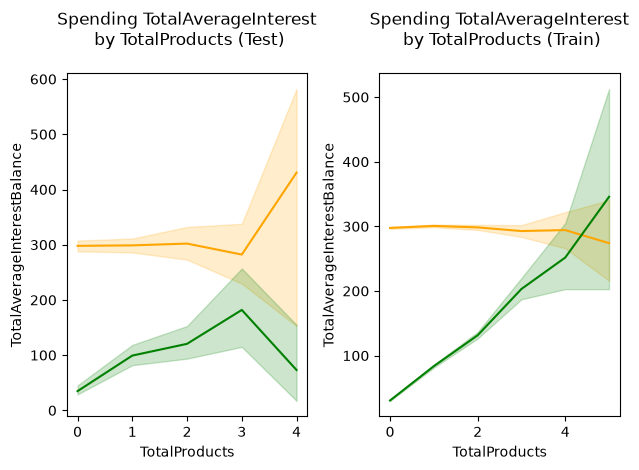

In [19]:
general_graphs.title = "Spending TotalAverageInterest\n by TotalProducts (Test)\n"
general_graphs.line_plot_two_lines(df_test, "TotalProducts", "TotalAverageInterestBalance", "TotalAverageInterest", 1,
                                   2, 1)
general_graphs.title = "Spending TotalAverageInterest\n by TotalProducts (Train)\n"
general_graphs.line_plot_two_lines(df_train, "TotalProducts", "TotalAverageInterestBalance", "TotalAverageInterest", 1,
                                   2, 2)
plt.tight_layout()
plt.show()

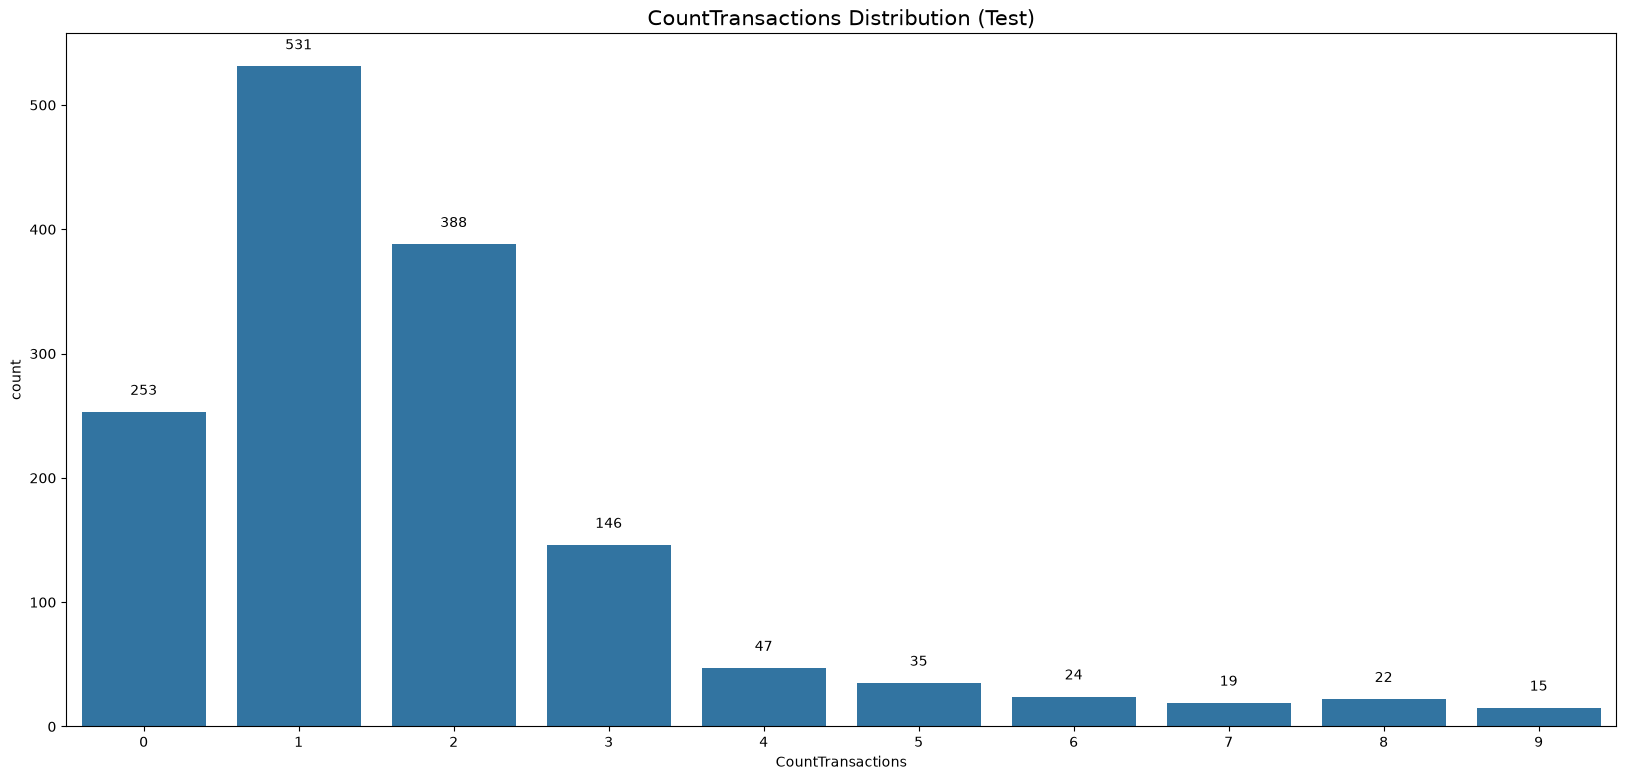

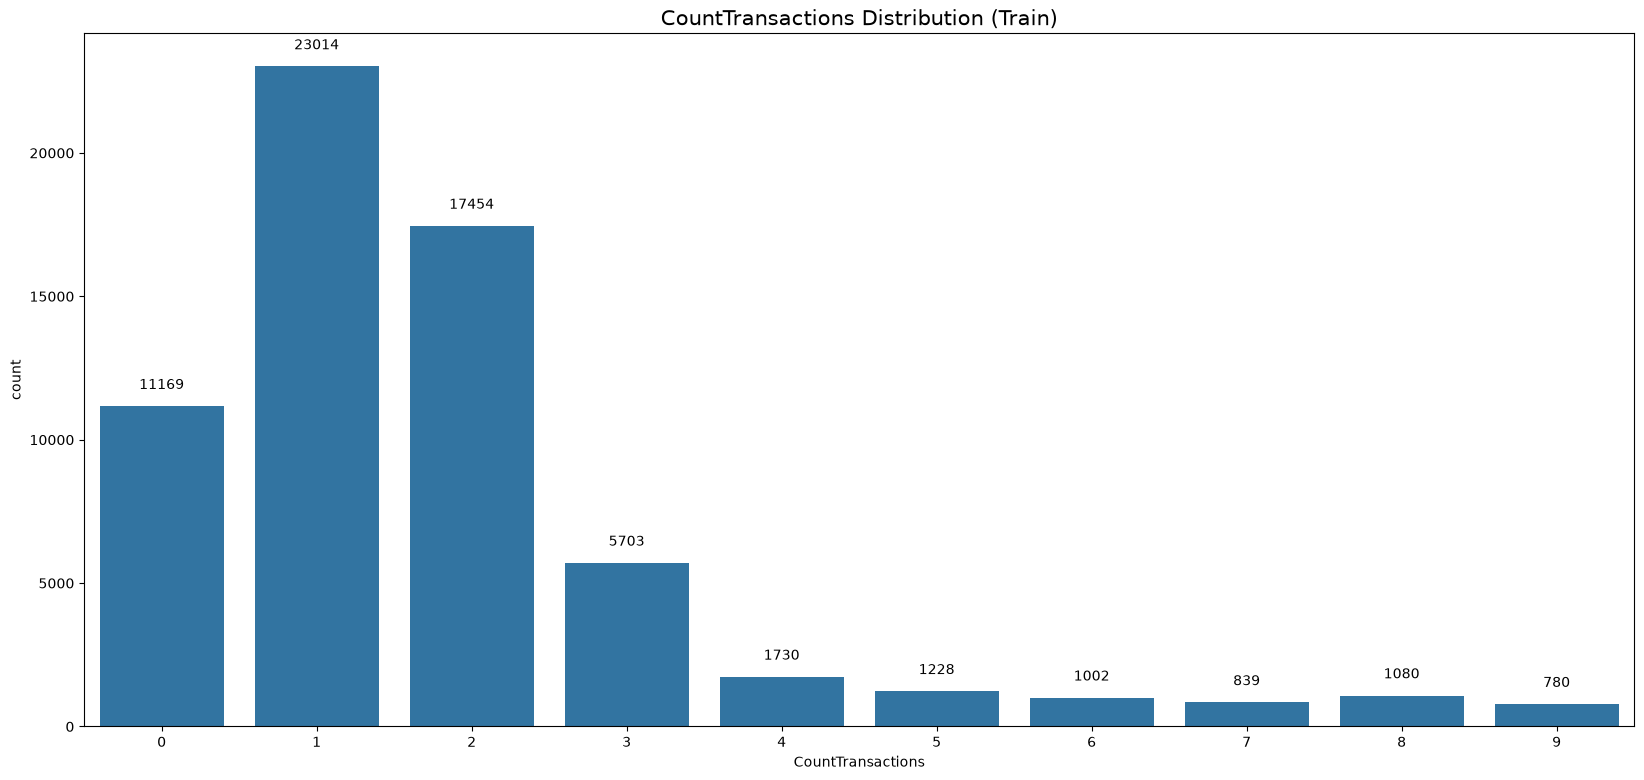

In [20]:
general_graphs.title = "CountTransactions Distribution (Test)"
general_graphs.count_plot(df_test, "CountTransactions")
general_graphs.title = "CountTransactions Distribution (Train)"
general_graphs.count_plot(df_train, "CountTransactions")

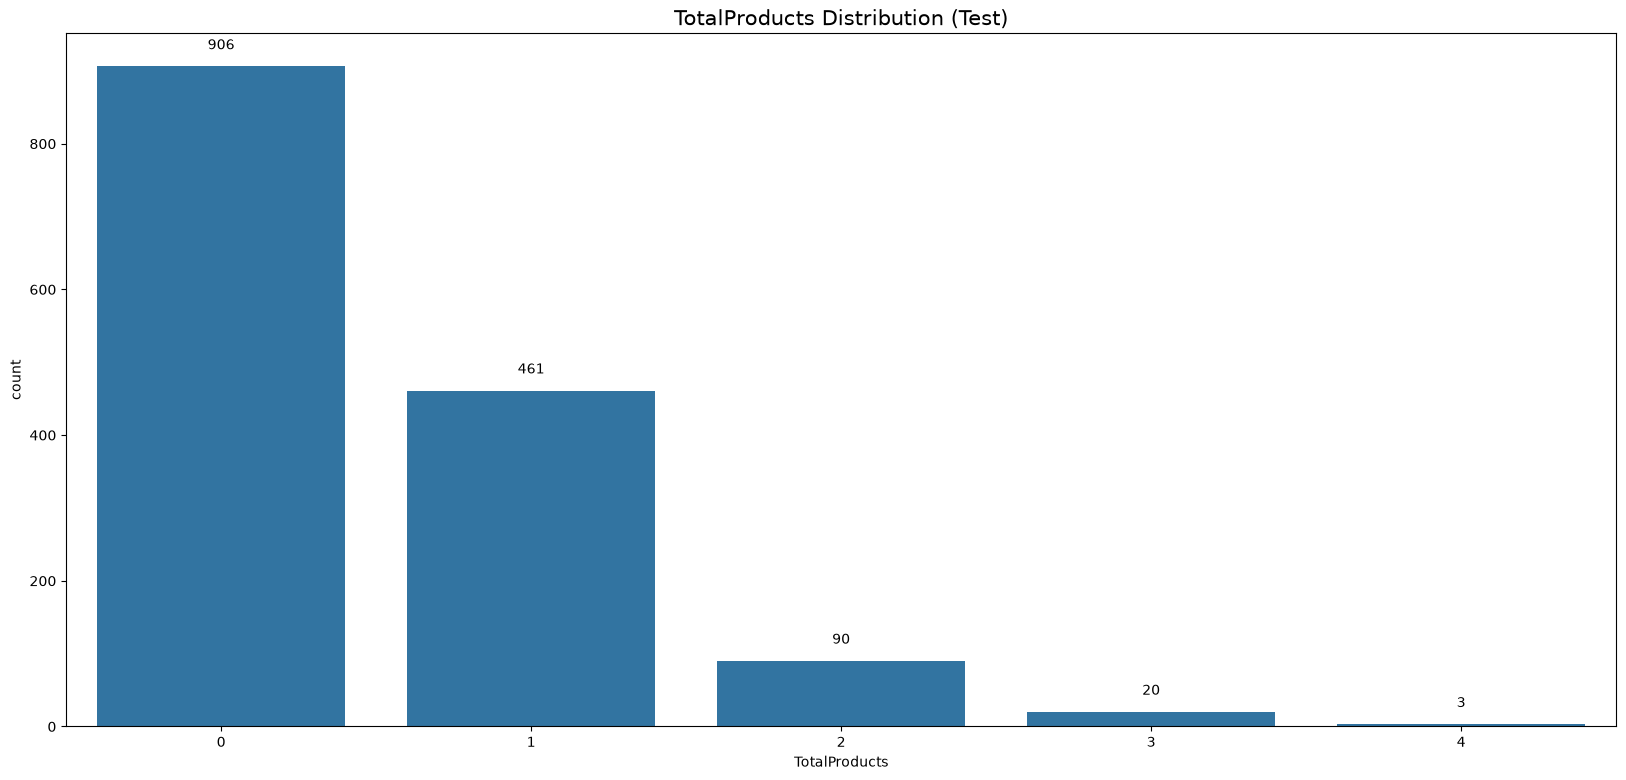

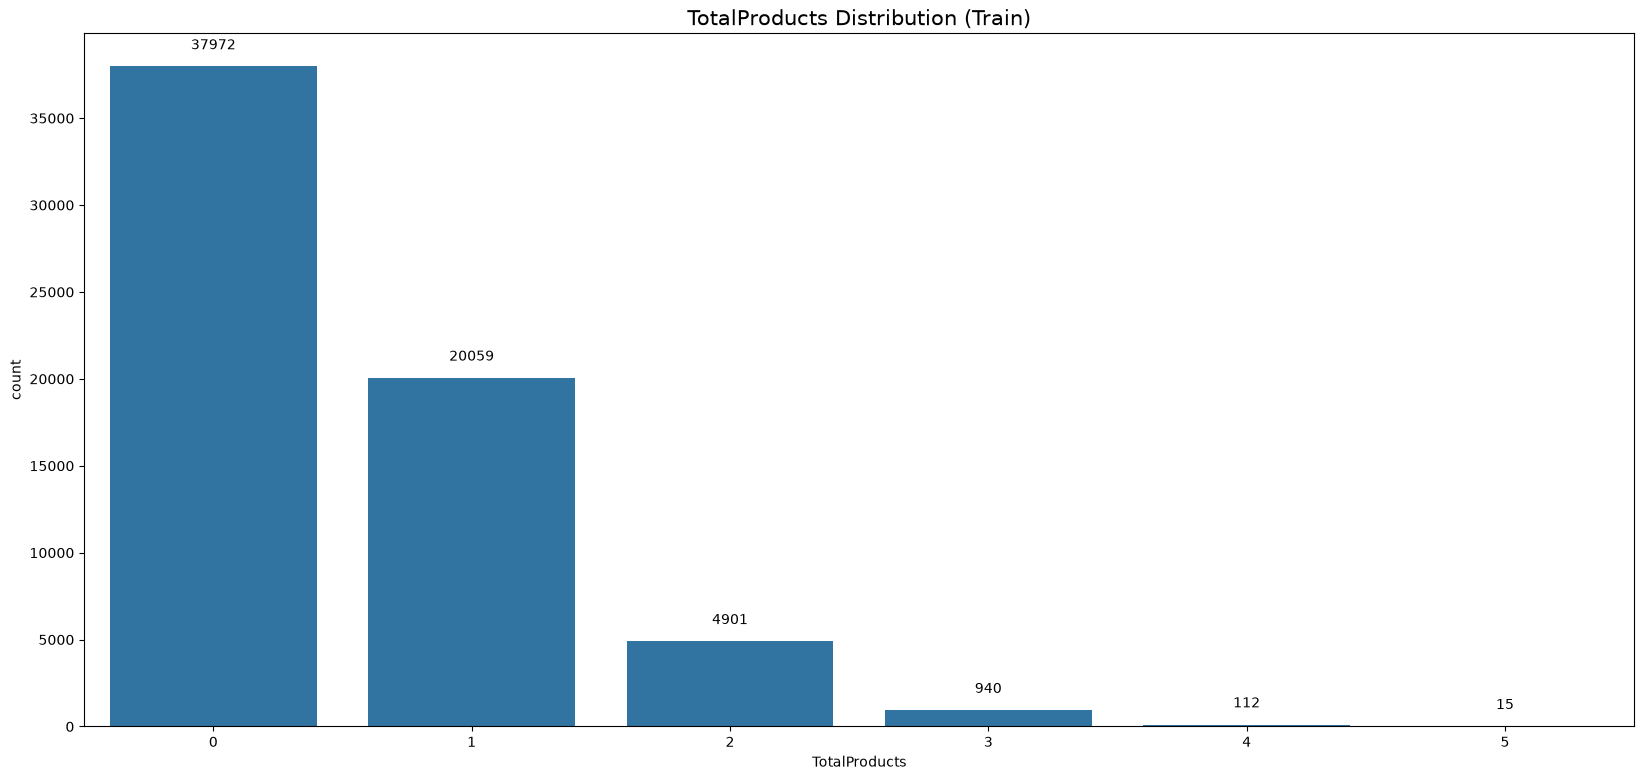

In [21]:
general_graphs.title = "TotalProducts Distribution (Test)"
general_graphs.count_plot(df_test, "TotalProducts")
general_graphs.title = "TotalProducts Distribution (Train)"
general_graphs.count_plot(df_train, "TotalProducts")

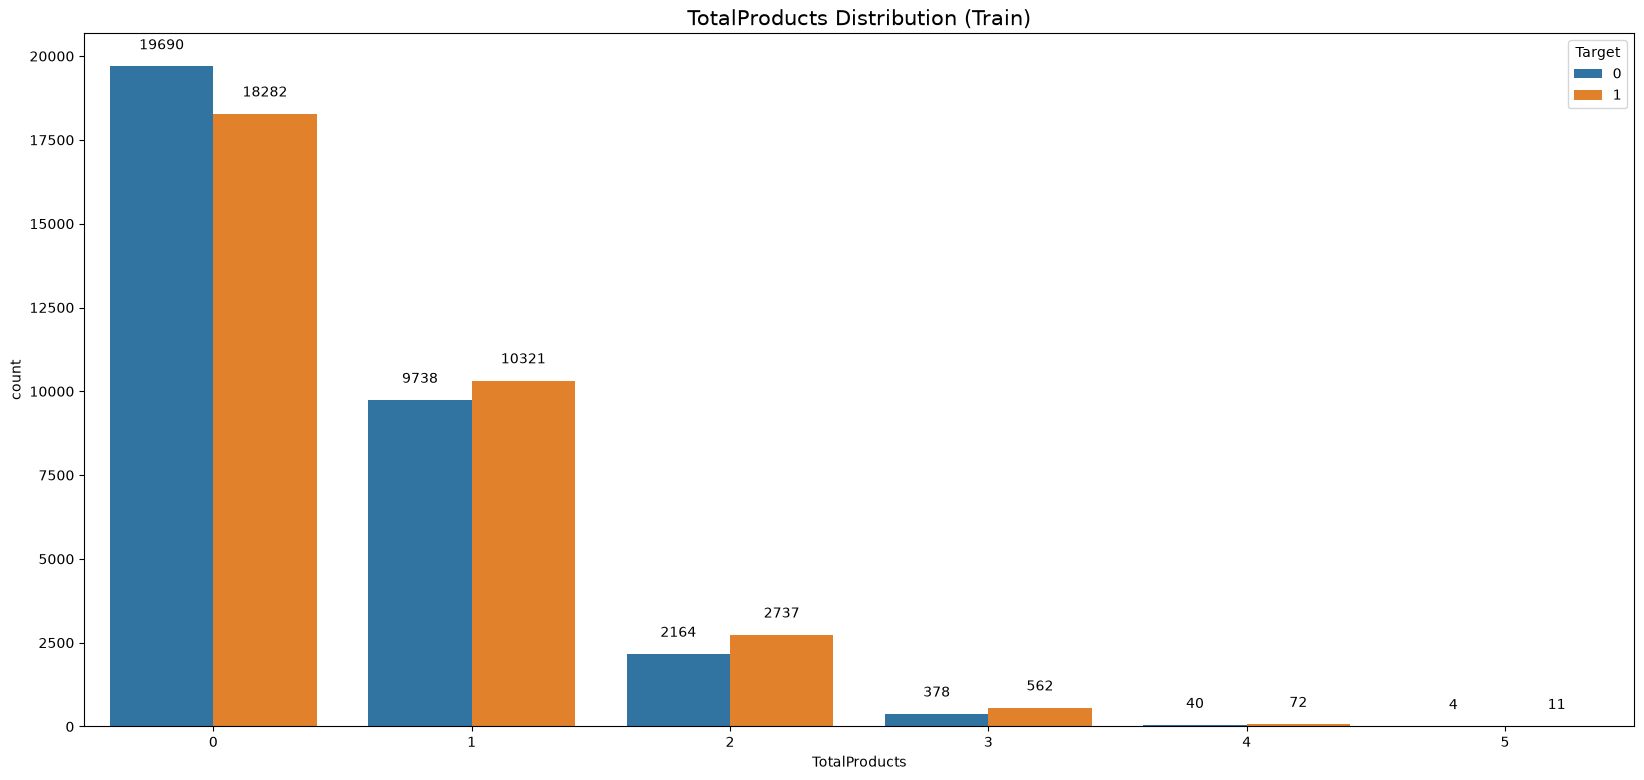

In [22]:
general_graphs.title = "TotalProducts Distribution (Train)"
general_graphs.count_plot(df_train, "TotalProducts", "Target")

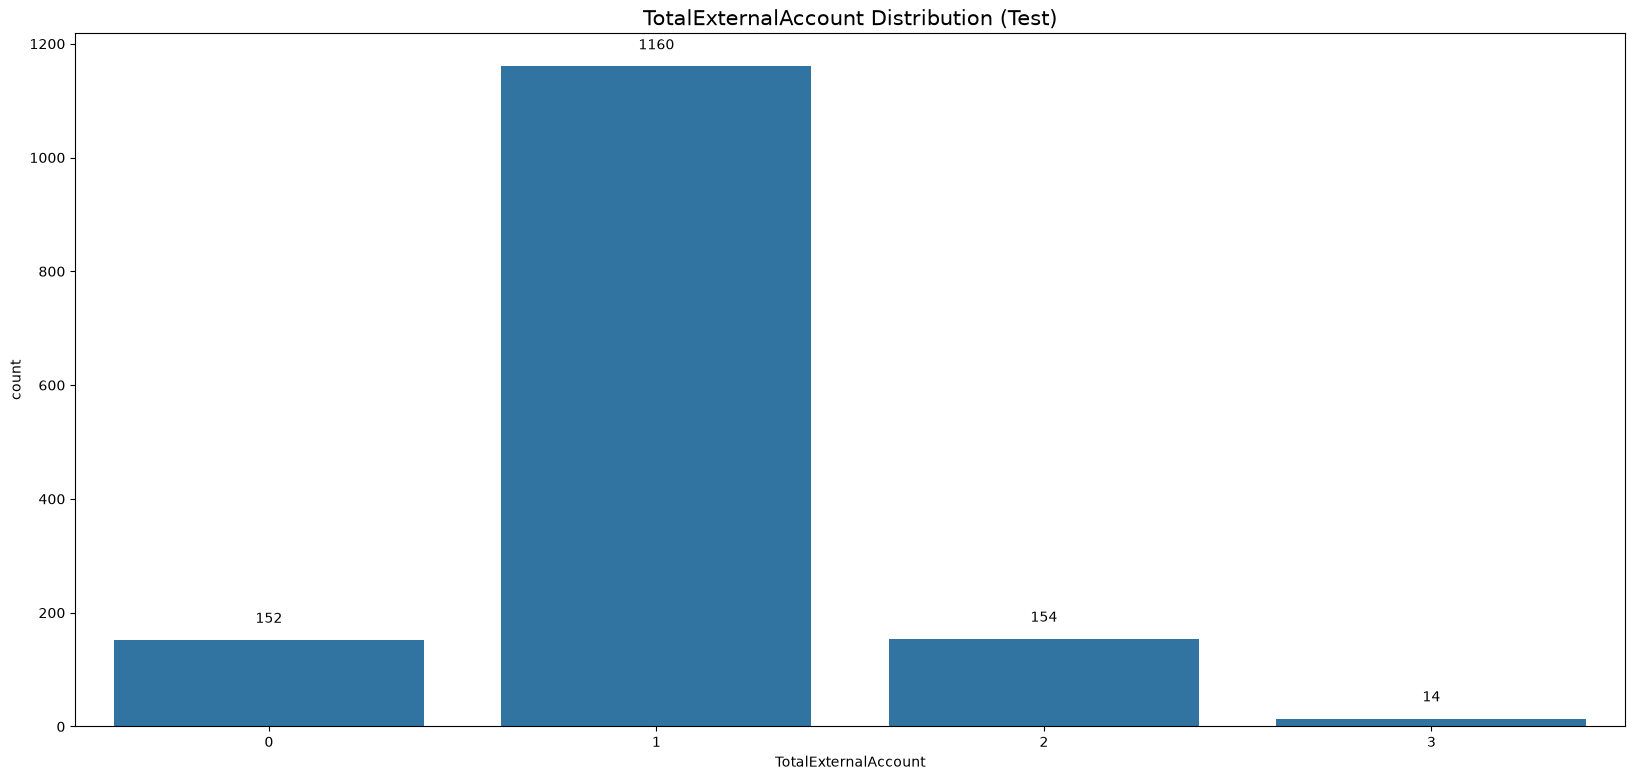

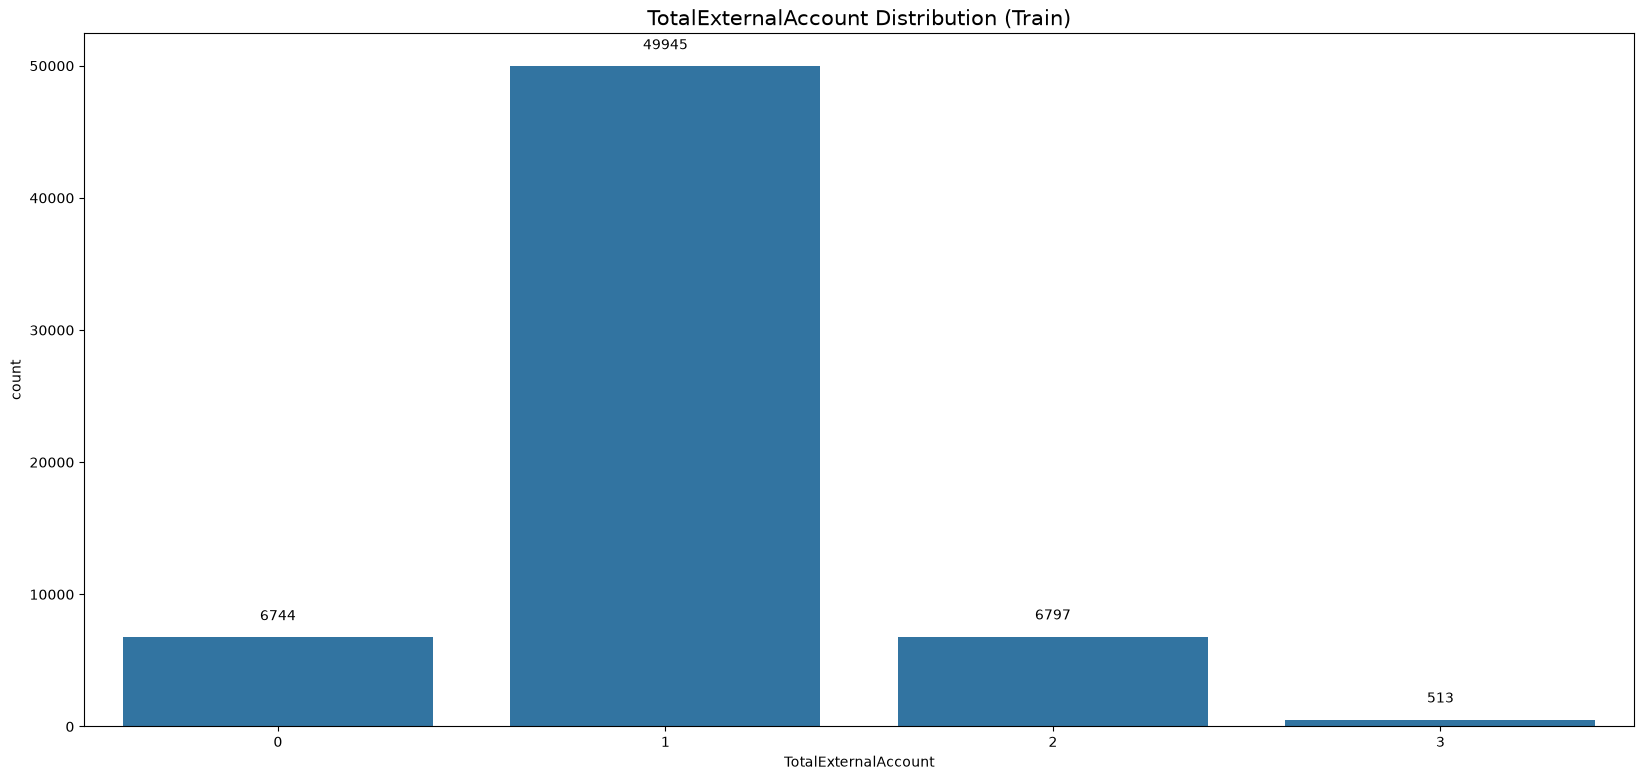

In [23]:
general_graphs.title = "TotalExternalAccount Distribution (Test)"
general_graphs.count_plot(df_test, "TotalExternalAccount")
general_graphs.title = "TotalExternalAccount Distribution (Train)"
general_graphs.count_plot(df_train, "TotalExternalAccount")

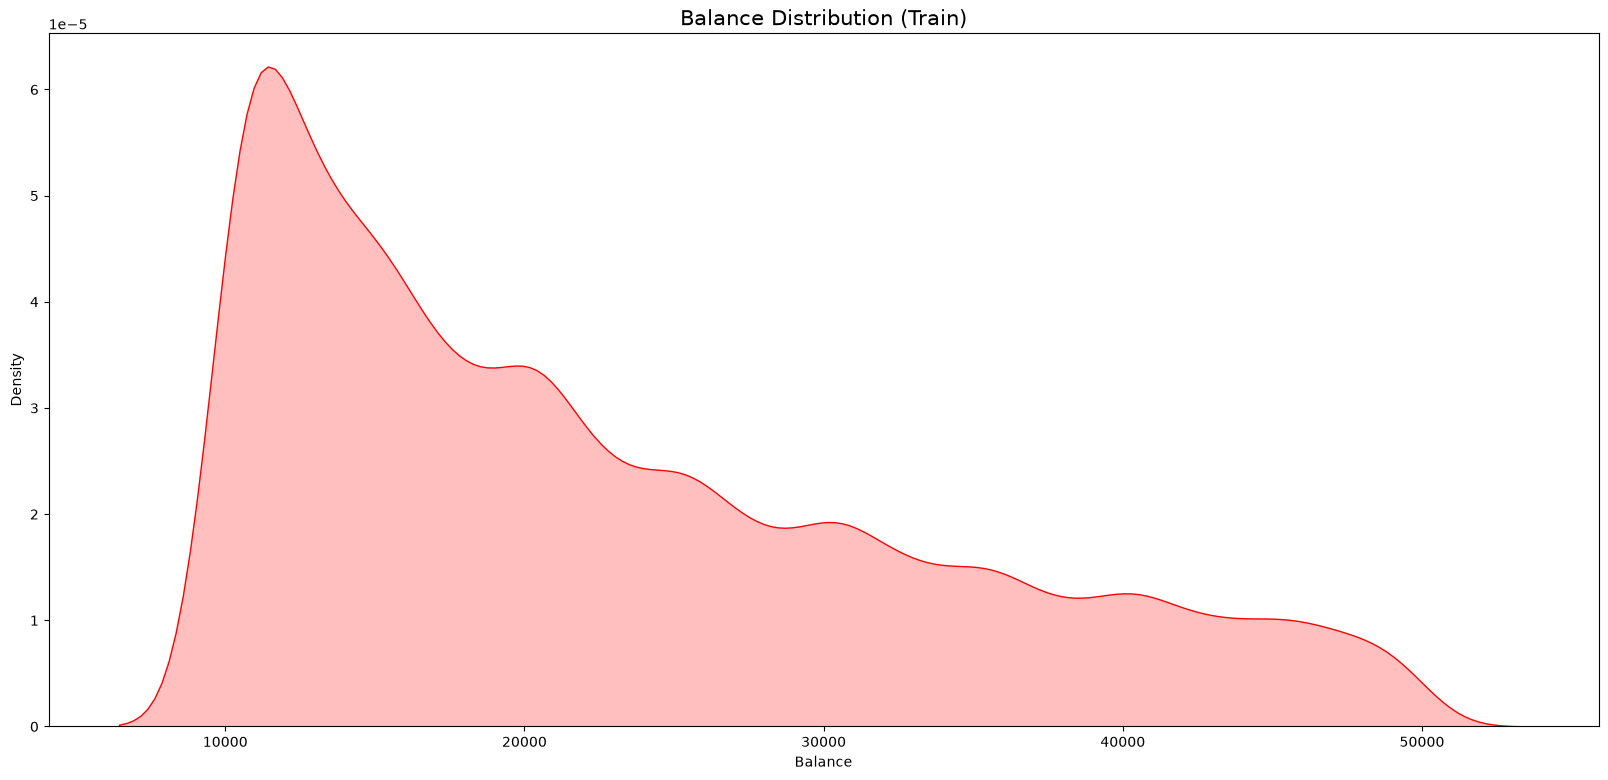

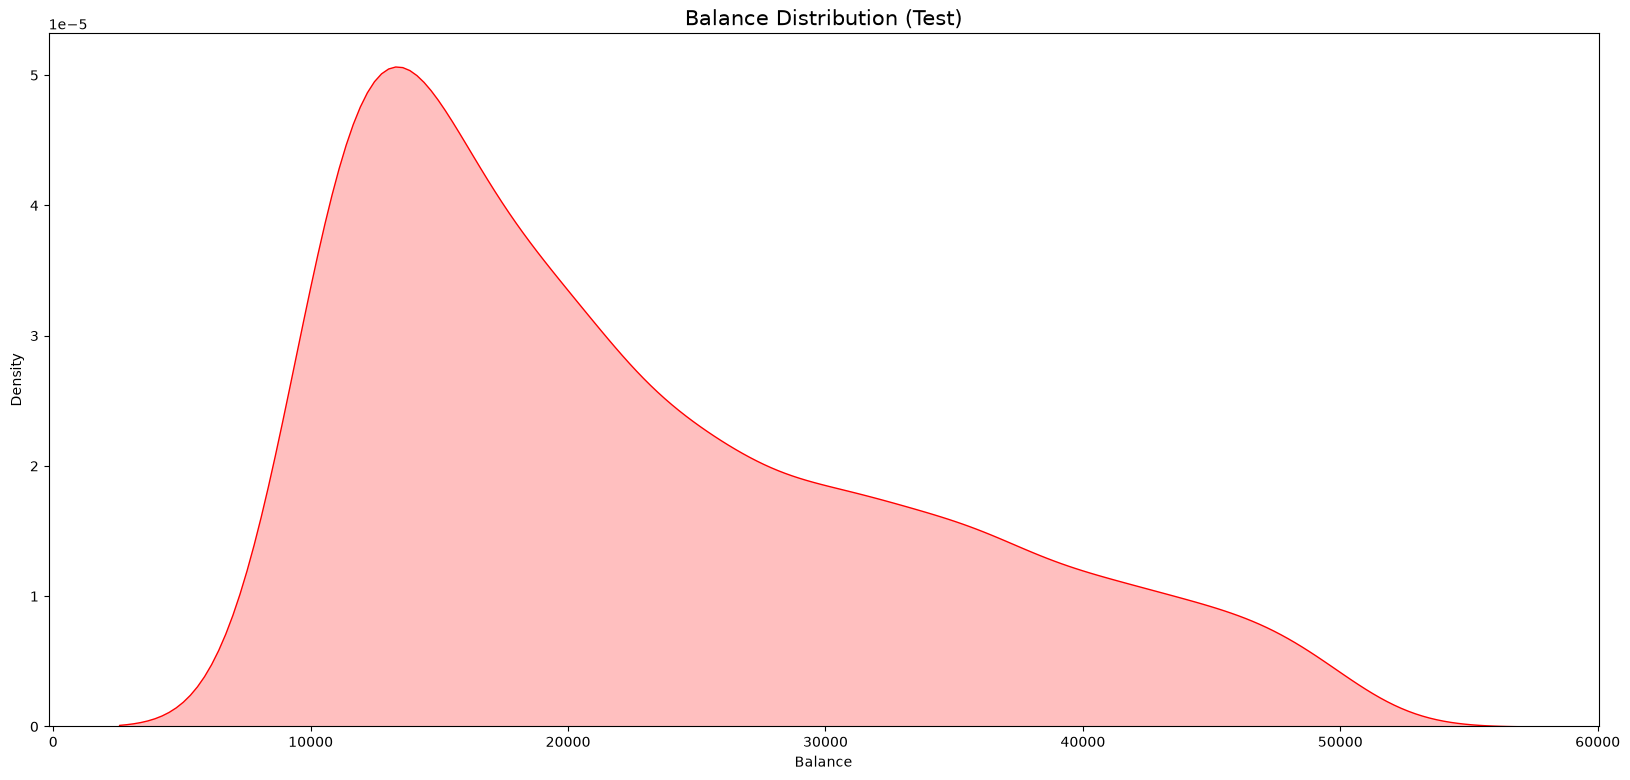

In [24]:
general_graphs.title = "Balance Distribution (Train)"
general_graphs.distribution_kdeplot(df_train, "Balance")
general_graphs.title = "Balance Distribution (Test)"
general_graphs.distribution_kdeplot(df_test, "Balance")

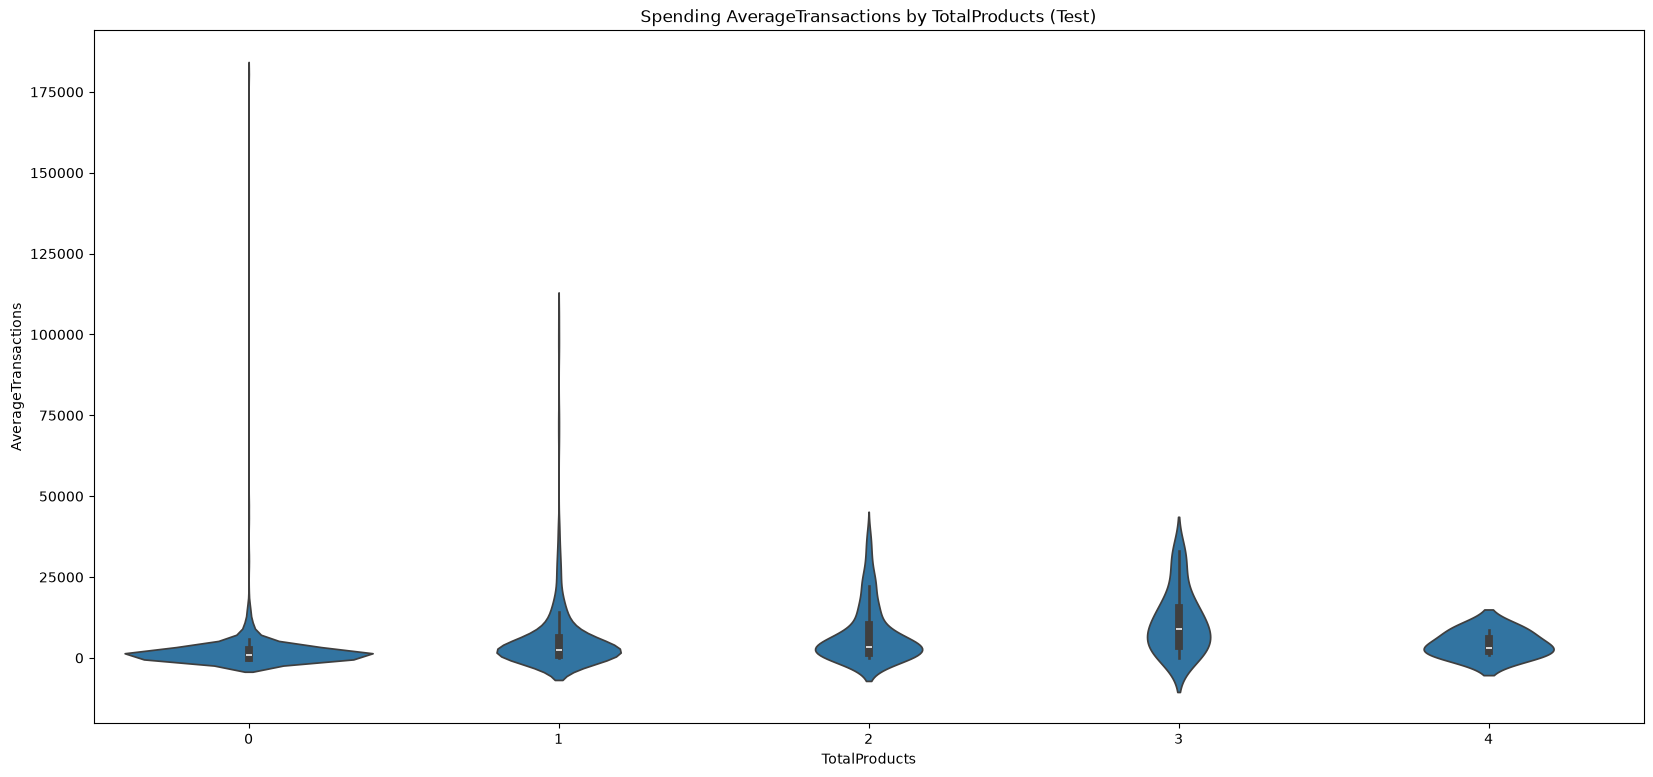

In [25]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.violinplot(x="TotalProducts", y="AverageTransactions", data=df_test, ax=ax)
plt.title("Spending AverageTransactions by TotalProducts (Test)")
plt.show()

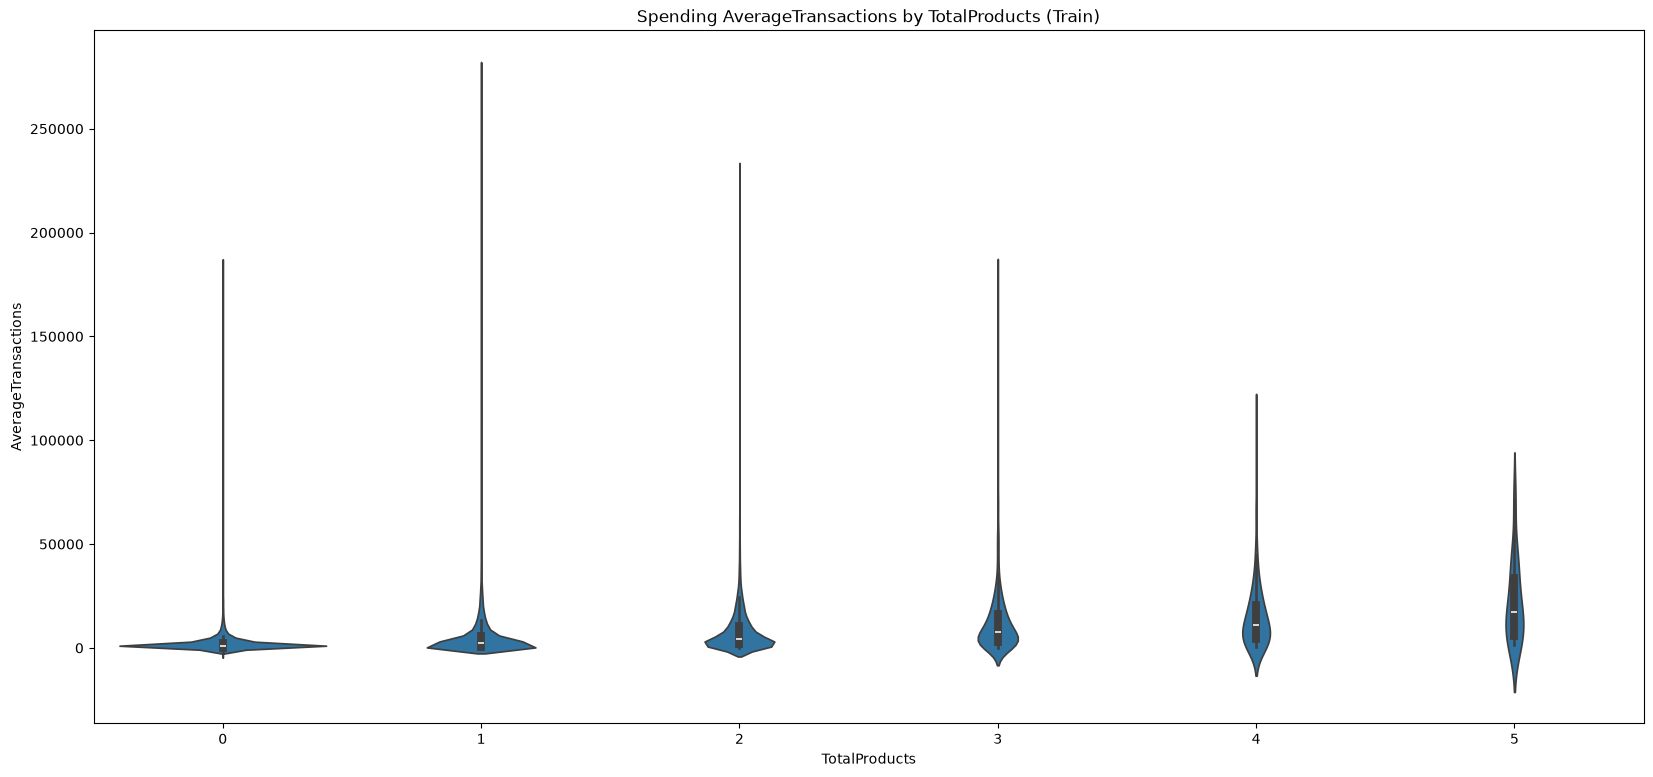

In [26]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.violinplot(x="TotalProducts", y="AverageTransactions", data=df_train, ax=ax)
plt.title("Spending AverageTransactions by TotalProducts (Train)")
plt.show()

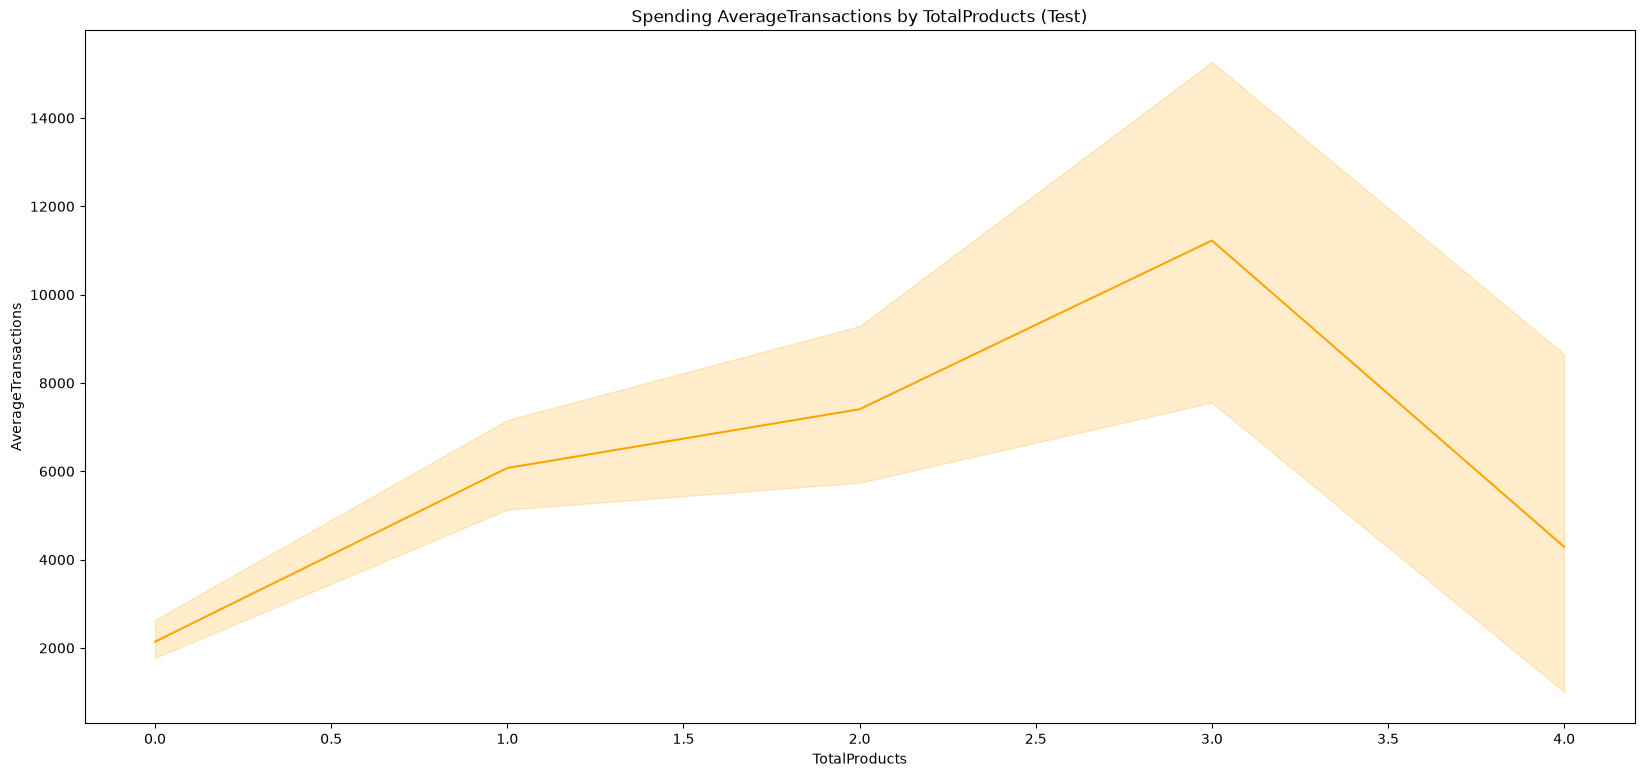

In [27]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts", y="AverageTransactions", color="orange", data=df_test, ax=ax
)
plt.title("Spending AverageTransactions by TotalProducts (Test)")
plt.show()

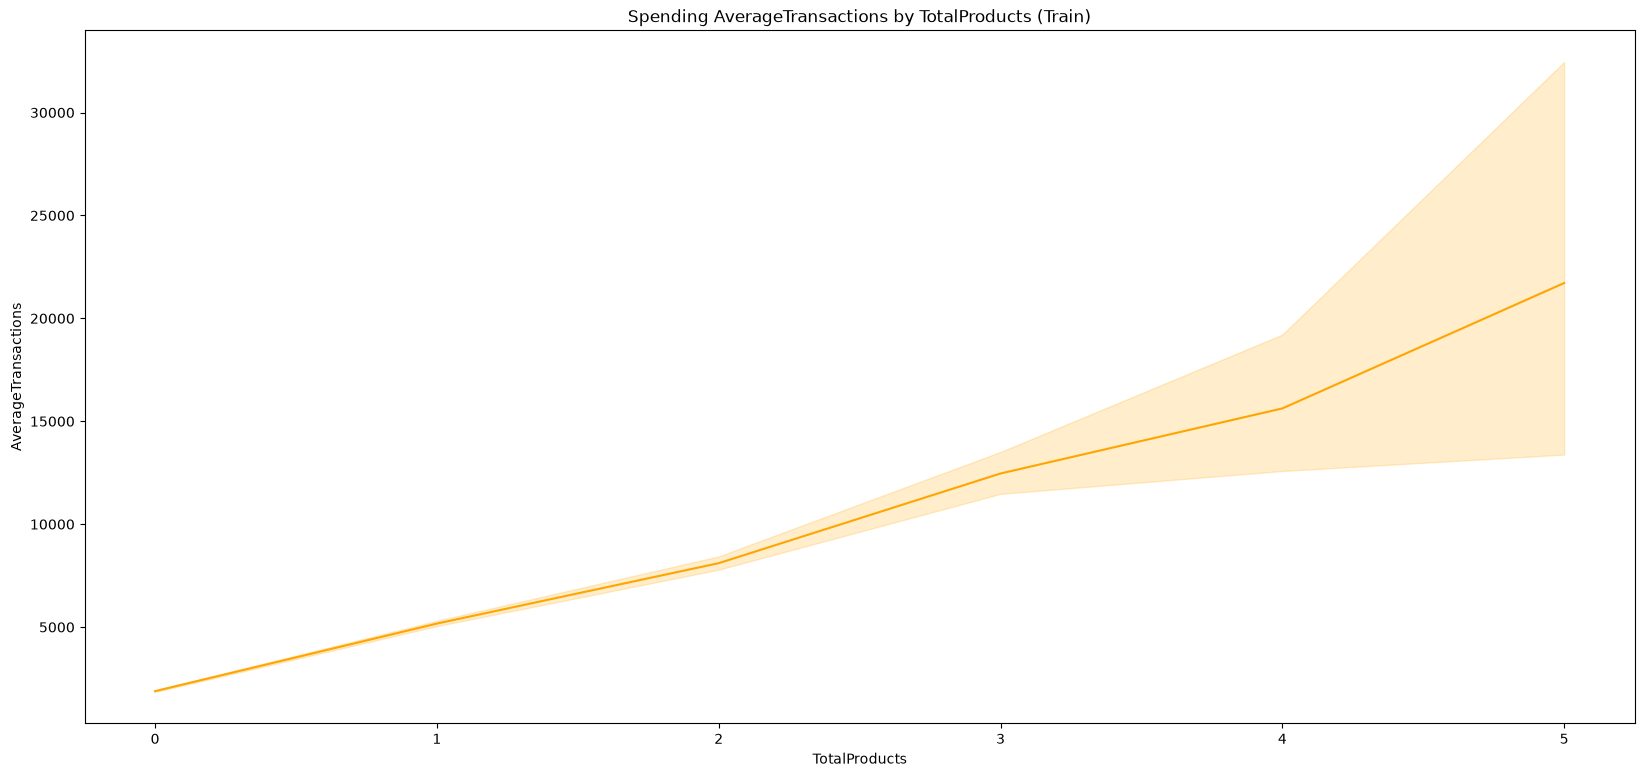

In [28]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts", y="AverageTransactions", color="orange", data=df_train, ax=ax
)
plt.title("Spending AverageTransactions by TotalProducts (Train)")
plt.show()

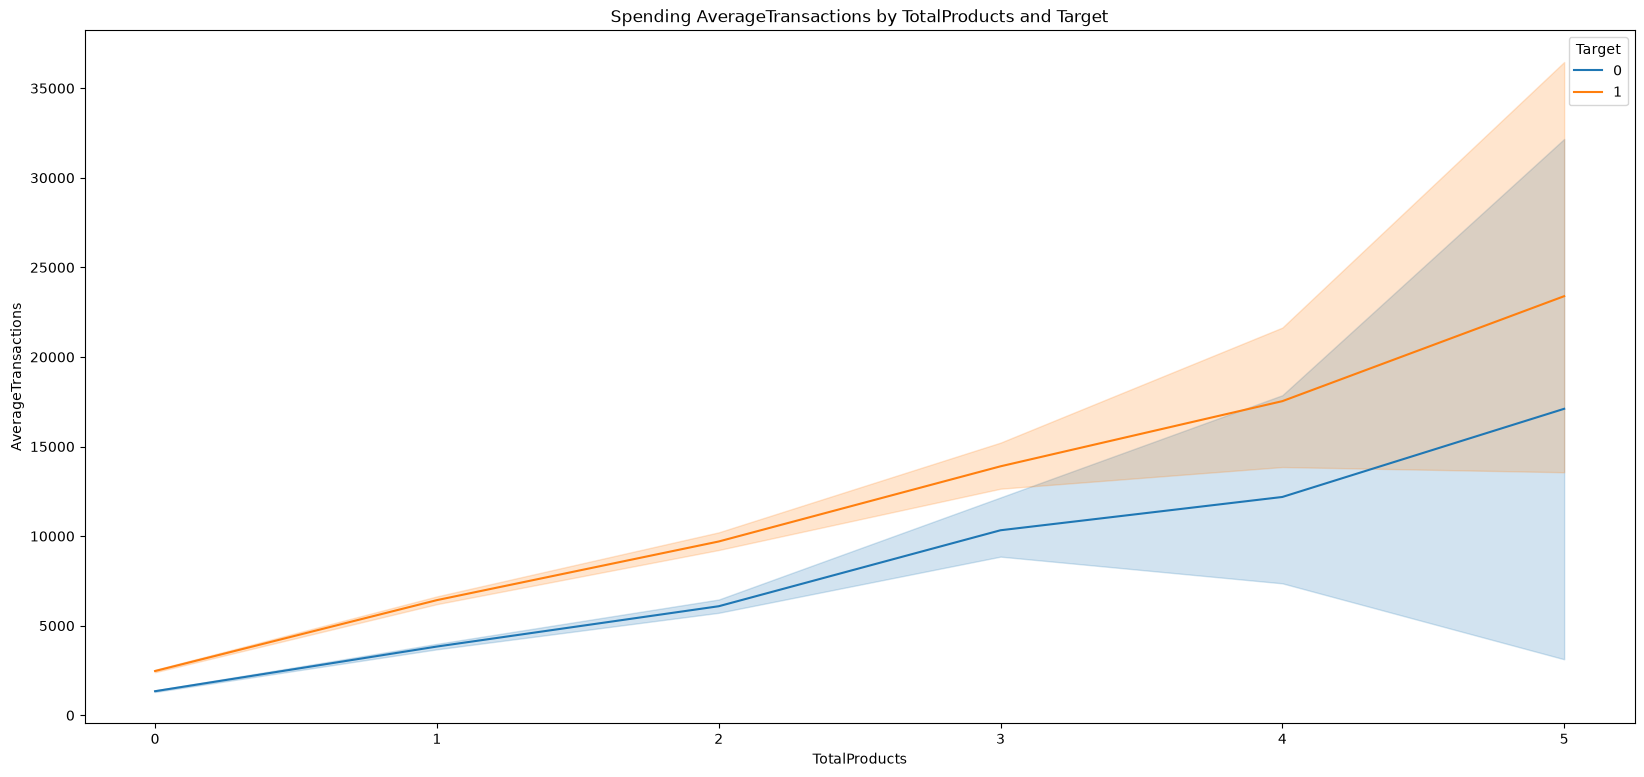

In [29]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts", y="AverageTransactions", hue="Target", data=df_train, ax=ax
)
plt.title("Spending AverageTransactions by TotalProducts and Target")
plt.show()

<Axes: >

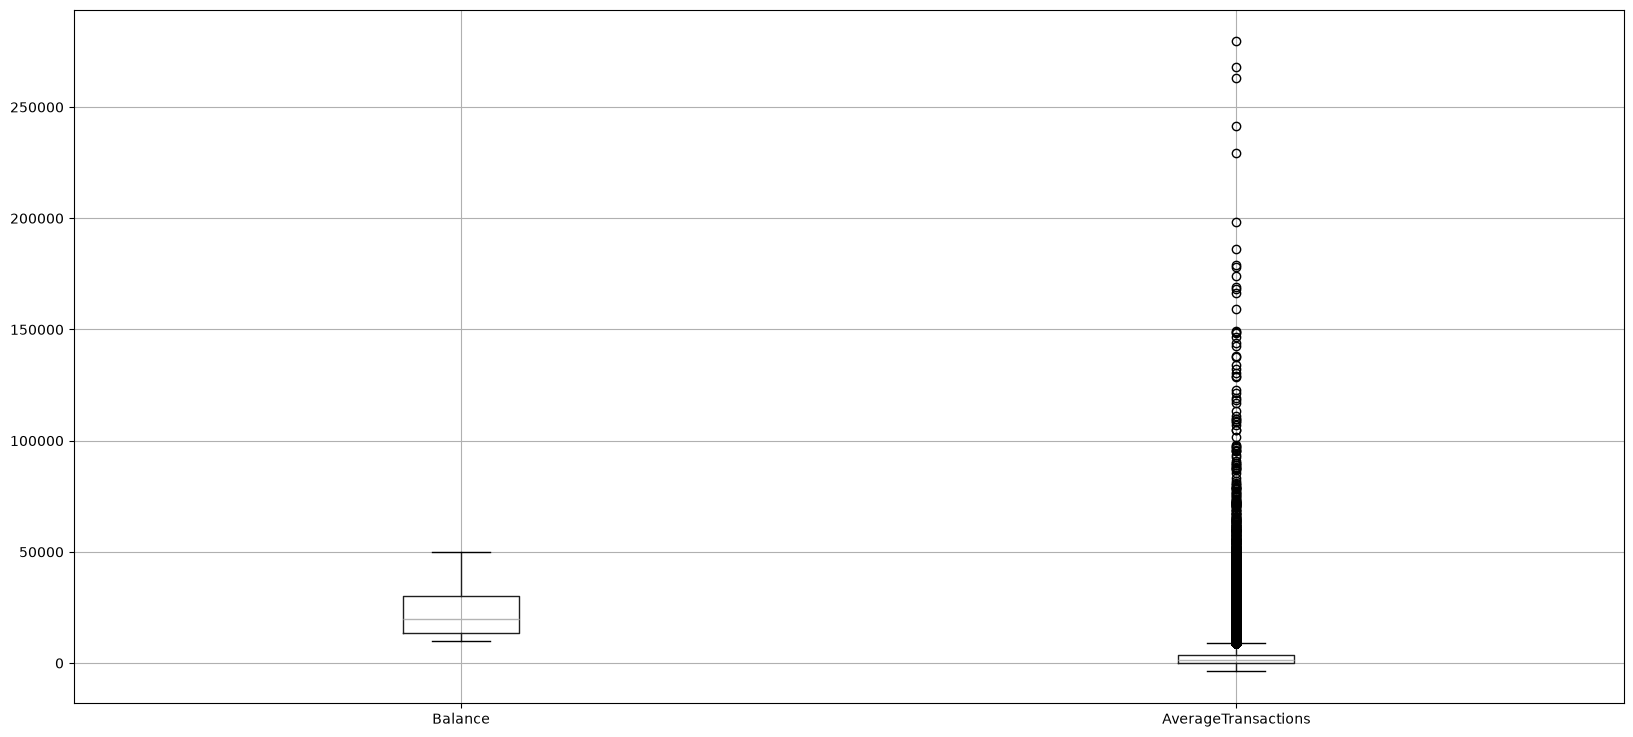

In [30]:
# distribution of the continuous variables
fig, ax = plt.subplots(figsize=(20, 9))
df_train.boxplot(
    column=["Balance", "AverageTransactions"],
    ax=ax,
)

<Axes: >

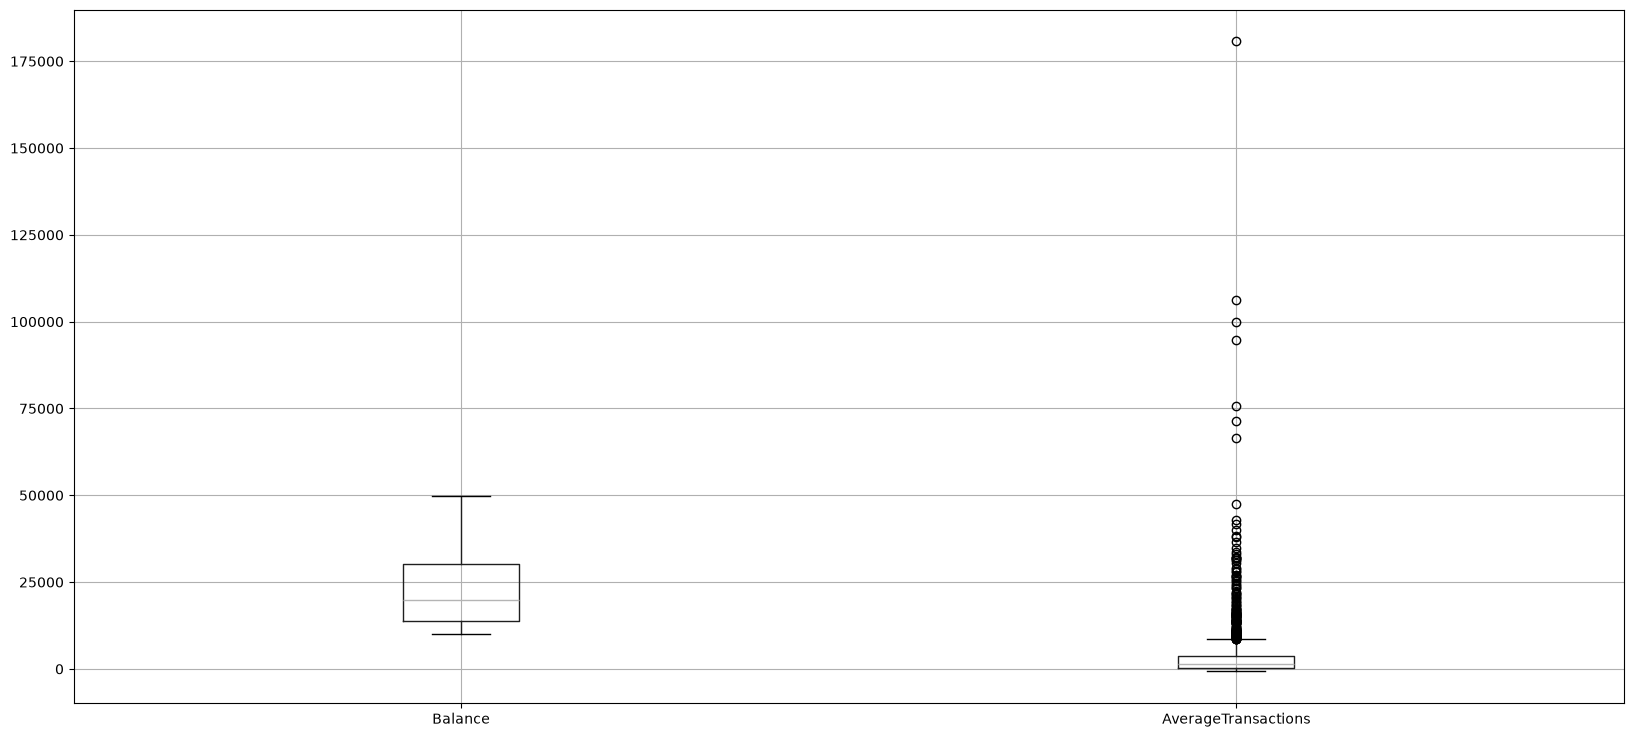

In [31]:
fig, ax = plt.subplots(figsize=(20, 9))
df_test.boxplot(
    column=["Balance", "AverageTransactions"],
    ax=ax,
)

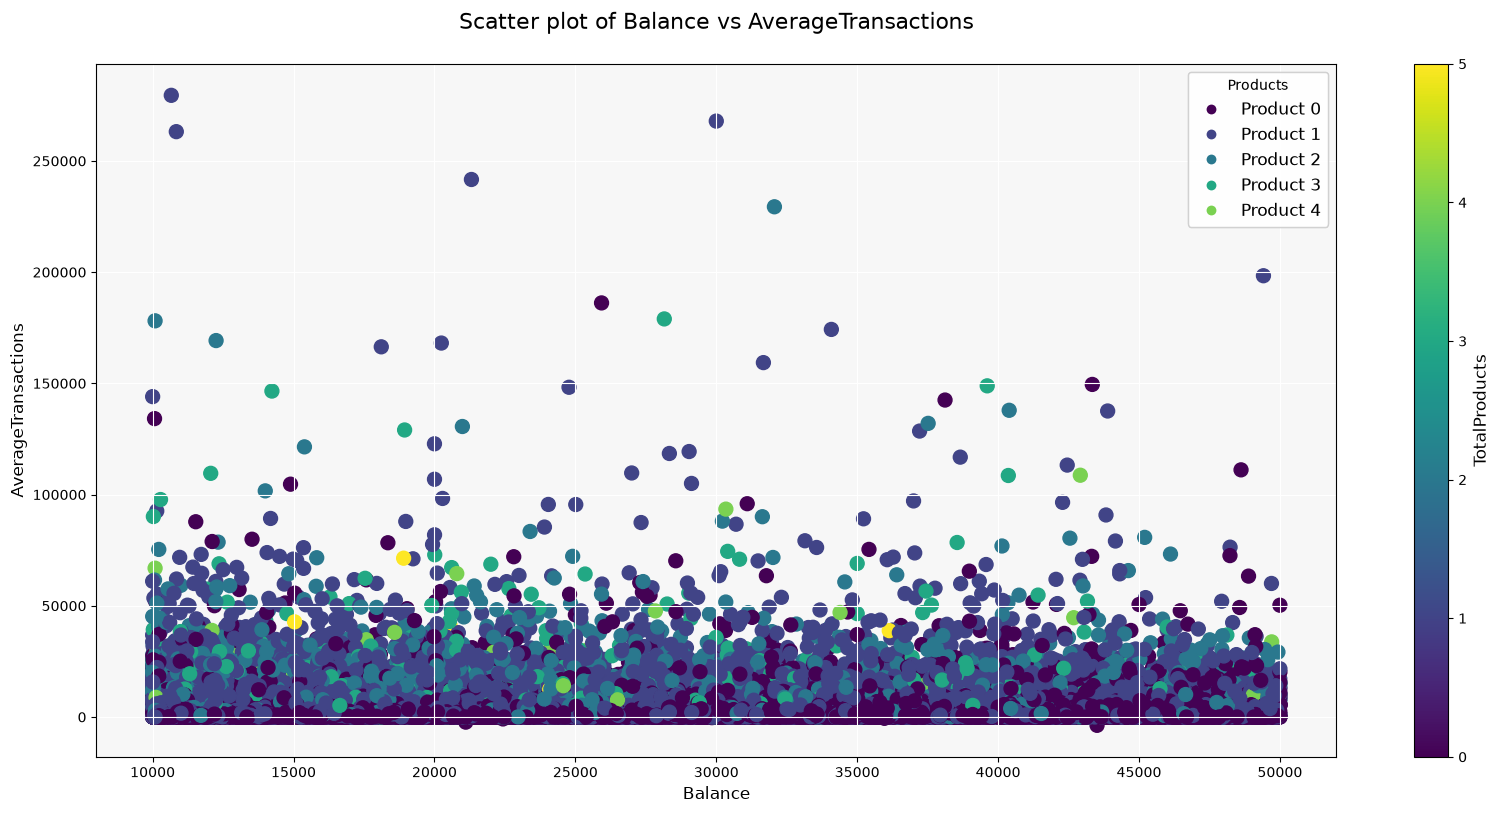

In [32]:
fig, ax = plt.subplots(figsize=(20, 9))
scatter = ax.scatter(
    df_train["Balance"],
    df_train["AverageTransactions"],
    c=df_train["TotalProducts"],
    cmap="viridis",
    s=100,
)

# Add labels and title
ax.set_xlabel("Balance", fontsize=12)
ax.set_ylabel("AverageTransactions", fontsize=12)
ax.set_title("Scatter plot of Balance vs AverageTransactions\n", fontsize=16)

# Add colorbar legend
cbar = fig.colorbar(scatter)
cbar.set_label("TotalProducts", fontsize=12)

# Set tick labels font size
ax.tick_params(axis="both", labelsize=10)

# Set plot background color and grid
ax.set_facecolor("#f7f7f7")
ax.grid(color="white")

# Create dictionary to map codes to species names
total_products_dict = {
    0: "Product 0",
    1: "Product 1",
    2: "Product 2",
    3: "Product 3",
    4: "Product 4",
}

# Add legend with species names
legend_handles, _ = scatter.legend_elements()
legend_labels = [
    total_products_dict[code] for code in df_test["TotalProducts"].unique()
]
legend = ax.legend(legend_handles, legend_labels, title="Products", fontsize=12)
ax.add_artist(legend)

# Show plot
plt.show()

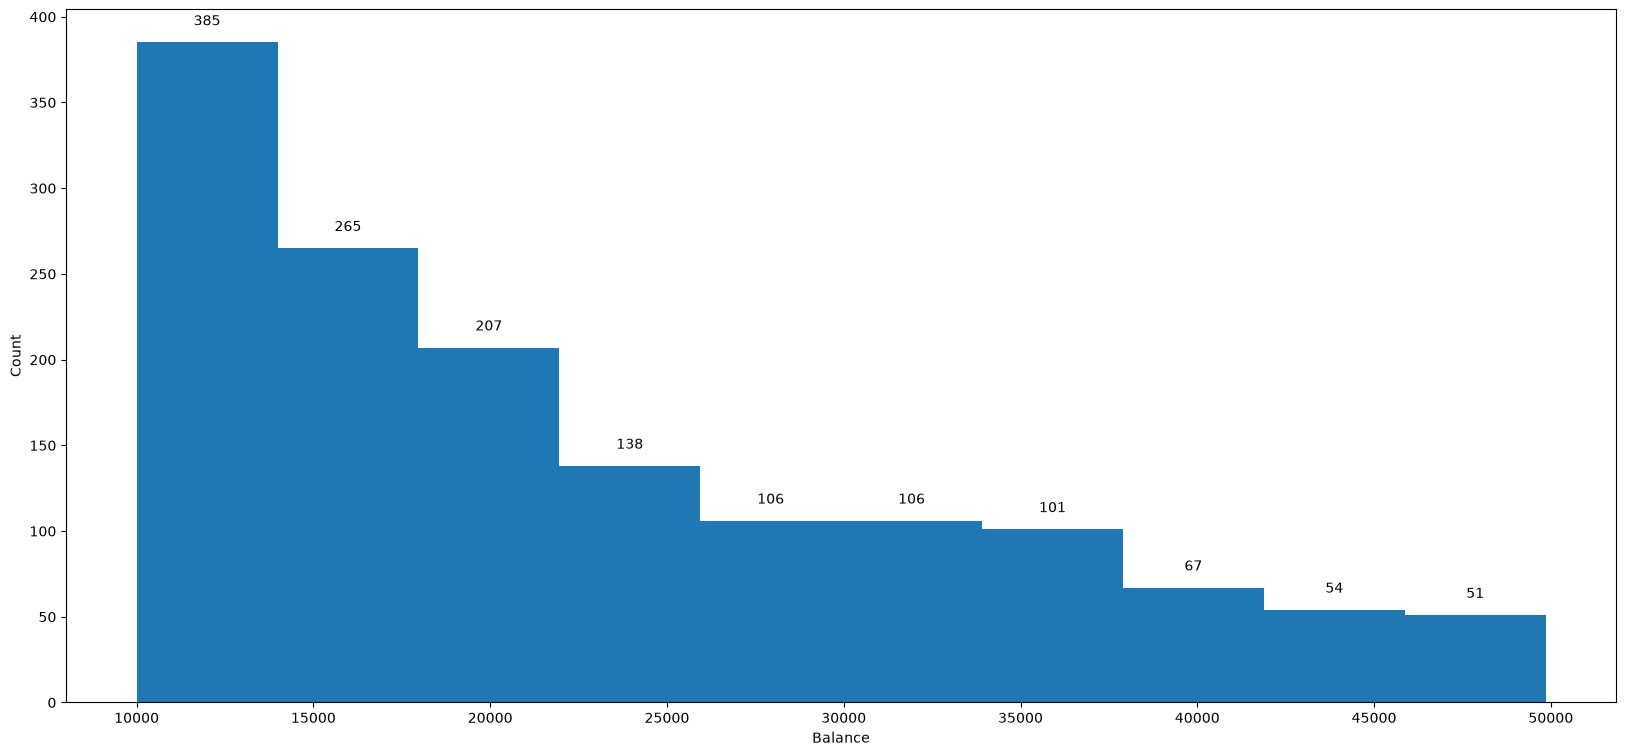

In [33]:
# Histogram
fig, ax = plt.subplots(figsize=(20, 9))
plt.hist(df_test["Balance"])
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.xlabel("Balance")
plt.ylabel("Count")
plt.show()

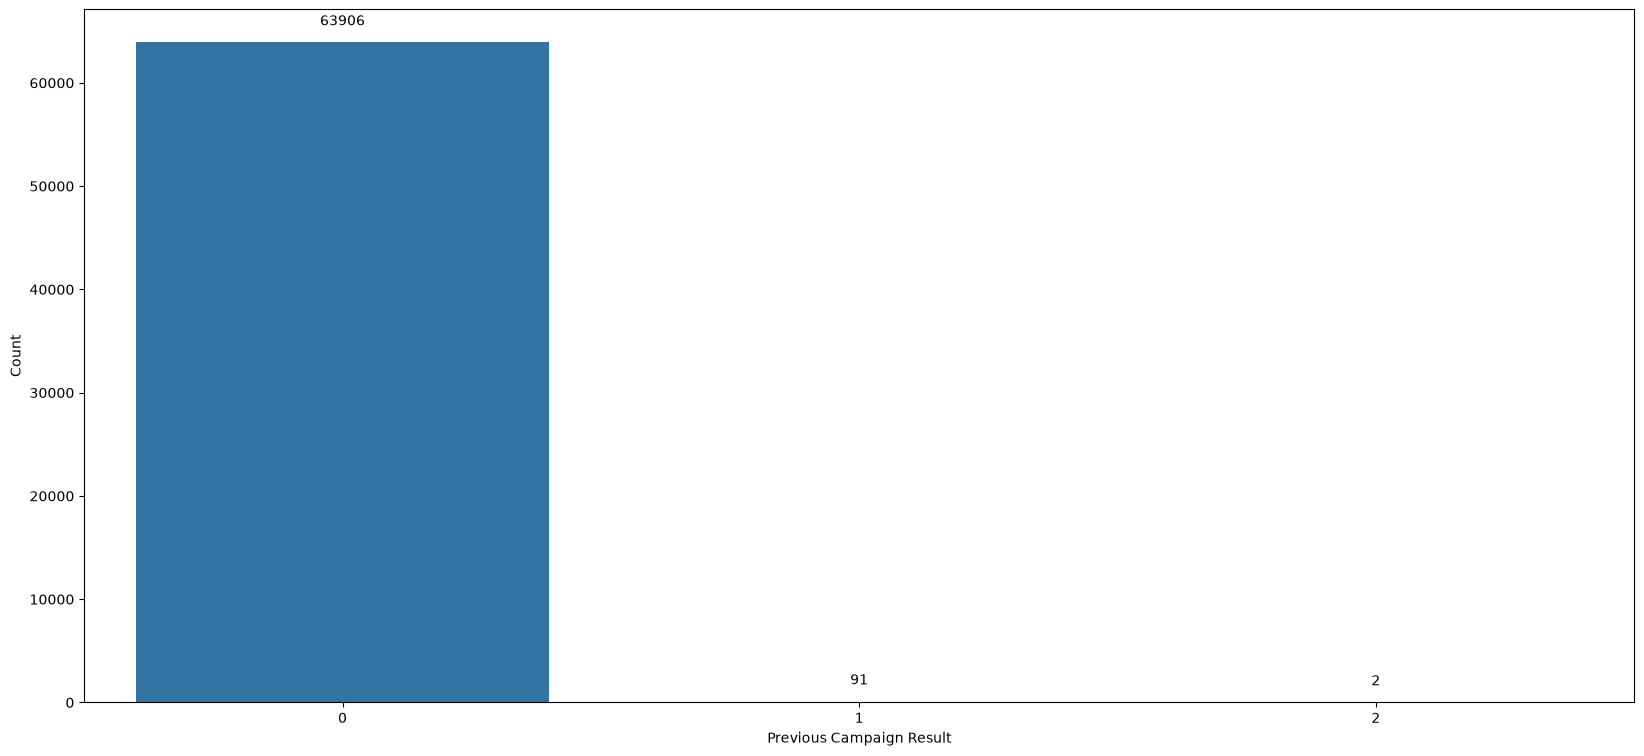

In [34]:
# Bar Chart
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="PreviousCampaignResult", data=df_train, ax=ax)
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.xlabel("Previous Campaign Result")
plt.ylabel("Count")
plt.show()

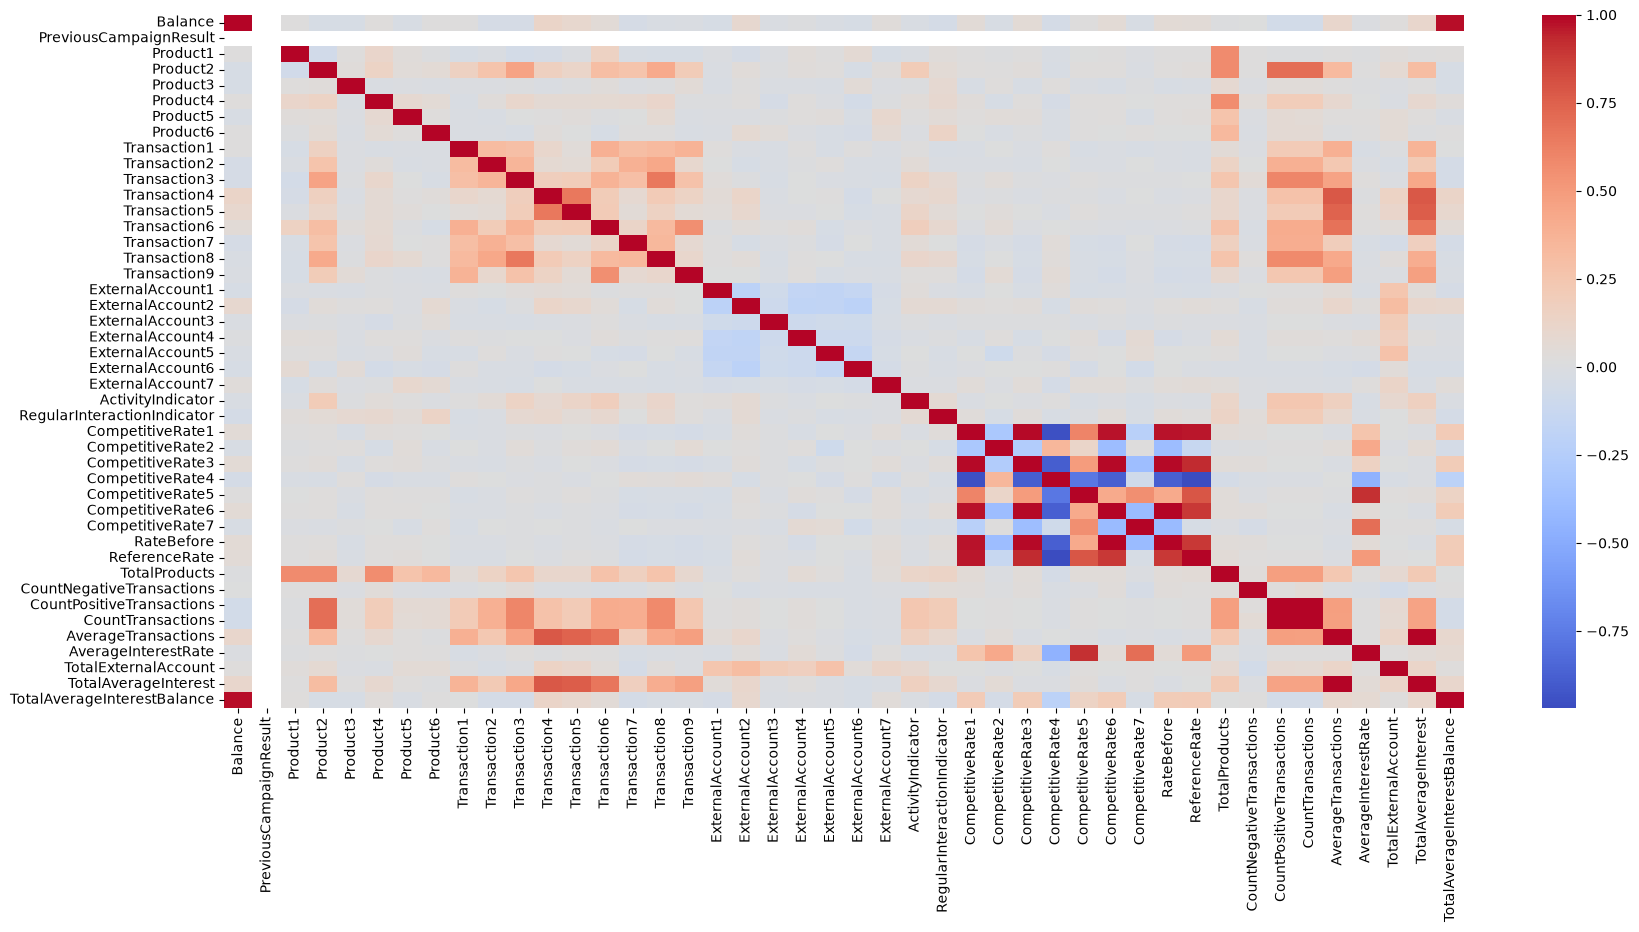

In [35]:
# Heatmap
corr = df_test.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(20, 9))
sns.heatmap(corr, cmap="coolwarm", ax=ax)
plt.show()

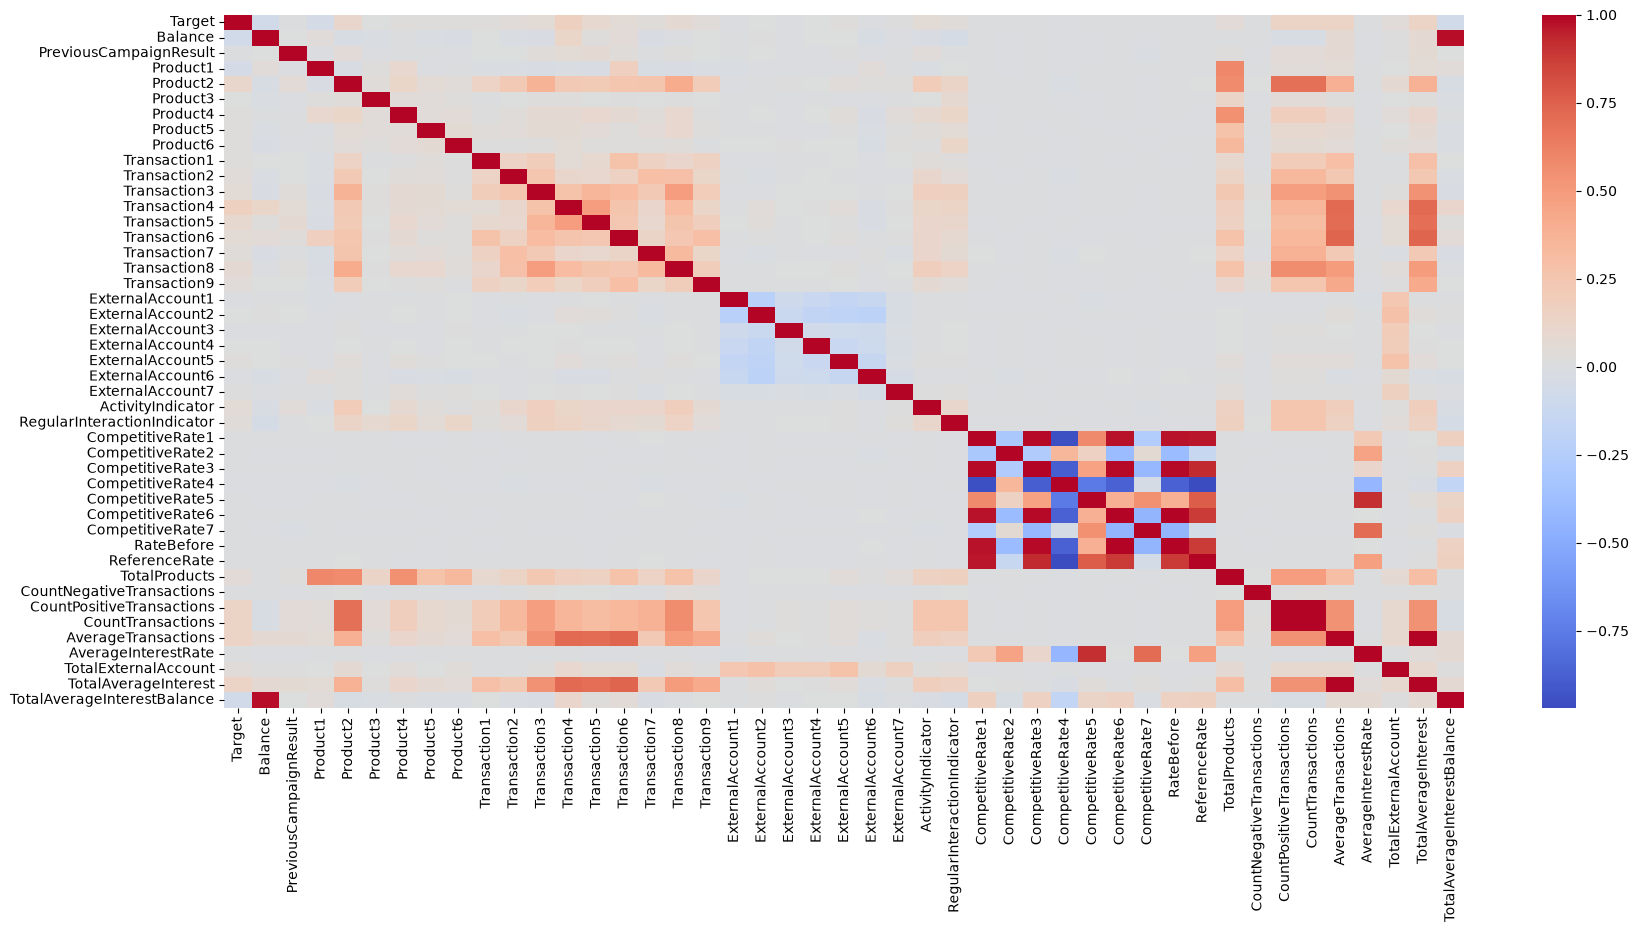

In [36]:
corr = df_train.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(20, 9))
sns.heatmap(corr, cmap="coolwarm", ax=ax)
plt.show()

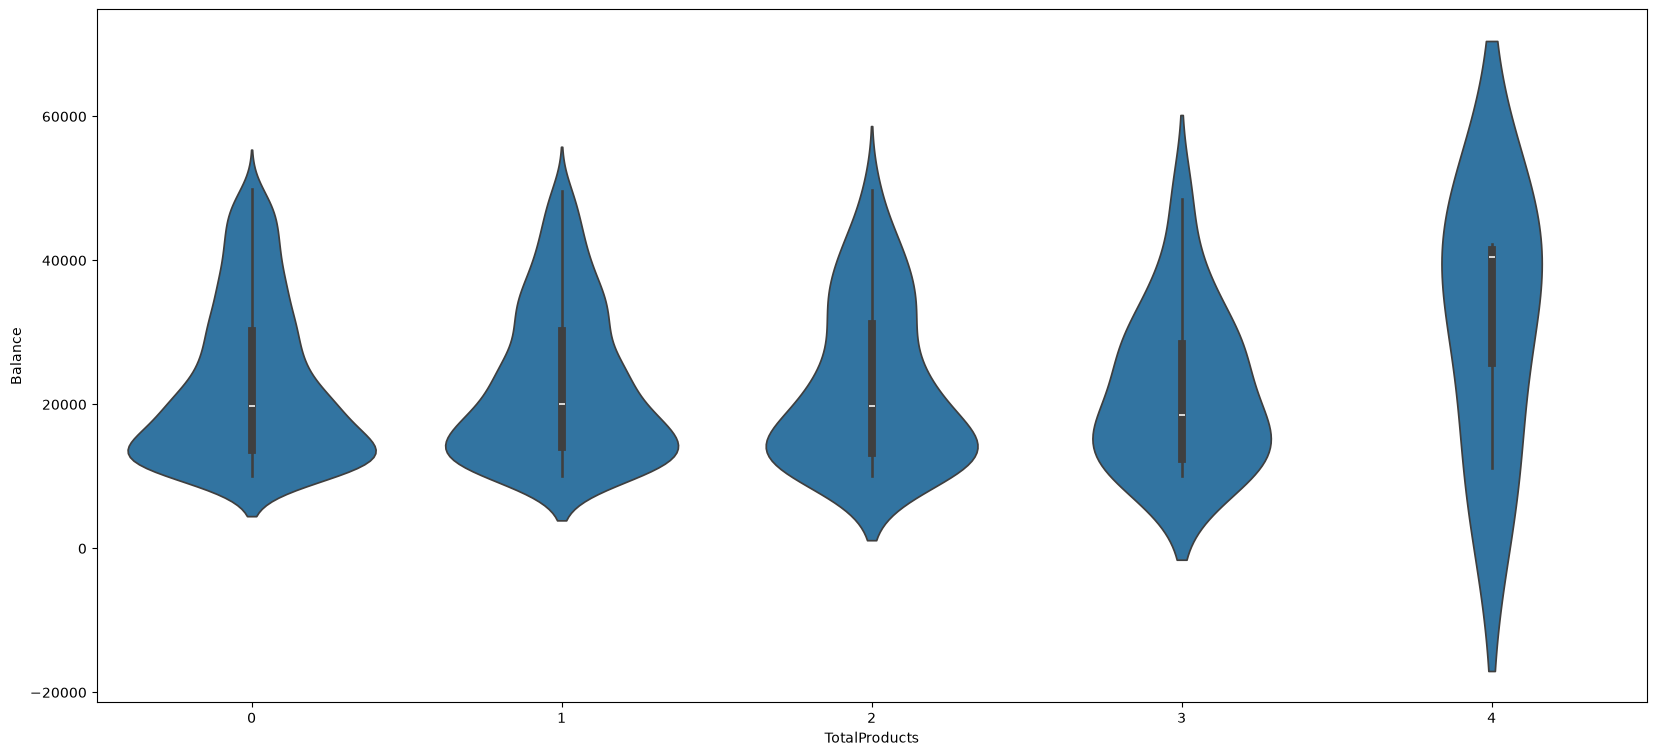

In [37]:
# Violin Plot
fig, ax = plt.subplots(figsize=(20, 9))
sns.violinplot(x="TotalProducts", y="Balance", data=df_test, ax=ax)
plt.xlabel("TotalProducts")
plt.ylabel("Balance")
plt.show()

# Cleansing

In [38]:
# Producs column list
list_products = df_train.loc[
                :, df_train.columns.str.startswith("Product")
                ].columns.values

# Copy dataset
df_train_cleaned = df_train.copy()

In [39]:
# Delete outliers with all methods to Products: AverageTransactions
for item in tqdm(list_products, desc="Products: AverageTransactions"):
    df_item = df_train_cleaned[df_train_cleaned[item] > 0]["AverageTransactions"]
    outlier_data = OutliersData(df_item)

    outliers = outlier_data.zr_score_outlier()
    outliers += outlier_data.z_score_outlier()
    outliers += outlier_data.iqr_outliers()
    outliers += outlier_data.winsorization_outliers()
    outliers += outlier_data.db_outliers()
    outliers += outlier_data.iso_outliers()
    df_train_cleaned.drop(
        df_train_cleaned[
            (df_train_cleaned["AverageTransactions"].isin(outliers))
            & df_train_cleaned[item]
            > 0
            ].index,
        inplace=True,
    )

del df_item
del outliers
del outlier_data

Products: AverageTransactions:   0%|          | 0/6 [00:00<?, ?it/s]

Products: AverageTransactions:  17%|█▋        | 1/6 [00:00<00:02,  2.16it/s]

Products: AverageTransactions:  33%|███▎      | 2/6 [00:00<00:01,  2.58it/s]

Products: AverageTransactions:  50%|█████     | 3/6 [00:00<00:00,  3.85it/s]

Products: AverageTransactions:  67%|██████▋   | 4/6 [00:01<00:00,  3.57it/s]

Products: AverageTransactions:  83%|████████▎ | 5/6 [00:01<00:00,  4.35it/s]

Products: AverageTransactions: 100%|██████████| 6/6 [00:01<00:00,  4.70it/s]

Products: AverageTransactions: 100%|██████████| 6/6 [00:01<00:00,  3.90it/s]

In [40]:
# Delete outliers with all methods to Products: Balance
for item in tqdm(list_products, desc="Products: Balance"):
    df_item = df_train_cleaned[df_train_cleaned[item] > 0]["Balance"]
    outlier_data = OutliersData(df_item)

    outliers = outlier_data.zr_score_outlier()
    outliers += outlier_data.z_score_outlier()
    outliers += outlier_data.iqr_outliers()
    outliers += outlier_data.winsorization_outliers()
    outliers += outlier_data.db_outliers()
    outliers += outlier_data.iso_outliers()
    df_train_cleaned.drop(
        df_train_cleaned[
            (df_train_cleaned["Balance"].isin(outliers)) & df_train_cleaned[item] > 0
            ].index,
        inplace=True,
    )

del df_item
del outliers
del outlier_data

Products: Balance:   0%|          | 0/6 [00:00<?, ?it/s]

Products: Balance:  17%|█▋        | 1/6 [00:00<00:01,  2.99it/s]

Products: Balance:  33%|███▎      | 2/6 [00:00<00:00,  4.14it/s]

Products: Balance:  67%|██████▋   | 4/6 [00:00<00:00,  7.20it/s]

Products: Balance:  83%|████████▎ | 5/6 [00:00<00:00,  7.48it/s]

Products: Balance: 100%|██████████| 6/6 [00:00<00:00,  7.42it/s]

Products: Balance: 100%|██████████| 6/6 [00:00<00:00,  6.47it/s]

In [41]:
# Keep only customers who were not contacted in a previous campaign (PreviousCampaignResult == 0).
# Every customer in test.csv has PreviousCampaignResult == 0, and only 93 training rows are different.
# (The earlier version used != 0, which kept only those few rows and left about 69 rows for training.)
df_train_cleaned = df_train_cleaned[df_train_cleaned["PreviousCampaignResult"] == 0]
print(f"Training rows after cleaning: {len(df_train_cleaned):,}")

Training rows after cleaning: 38,270


In [42]:
# Delete PreviousCampaignResult
df_train_cleaned.drop(columns=["PreviousCampaignResult"], inplace=True)

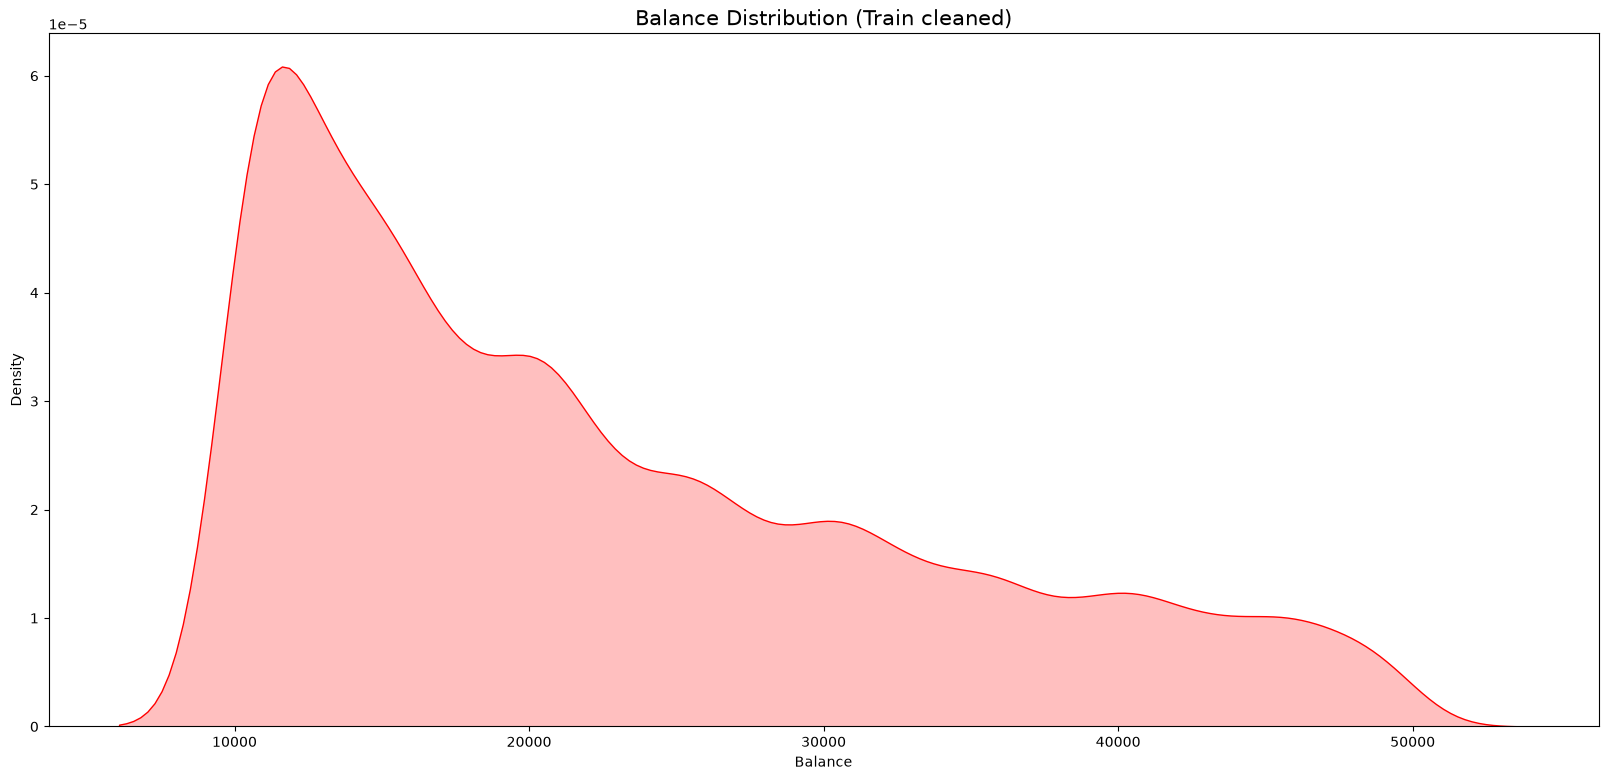

In [43]:
general_graphs.title = "Balance Distribution (Train cleaned)"
general_graphs.distribution_kdeplot(df_train_cleaned, "Balance")

In [44]:
df_test.groupby(by=["PreviousCampaignResult"], as_index=False)[
    ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
].sum()

,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6
0,0,271,238,2,121,24,57


In [45]:
df_train.groupby(by=["Target", "PreviousCampaignResult"], as_index=False)[
    ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
].sum()

,Target,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6
0,0,0,7035,3869,39,2656,564,1175
1,0,1,7,25,0,8,1,1
2,1,0,5781,6342,74,3230,848,1501
3,1,1,5,31,0,4,3,3
4,1,2,0,2,0,0,0,0


In [46]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[
    [
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
    ]
].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[
    [
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
    ]
].sum()

In [47]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,Target
0,0,733629.46,147335.47,1156773.3,21445705.51,9687102.86,13126441.11,146564.05,2248978.04,2120120.77,2


In [48]:
group_train_campaign_result

,Target,PreviousCampaignResult,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9
0,0,0,5777994.85,1872849.91,19822015.24,2.912308e+08,1.246974e+08,2.274376e+08,2259044.21,31851746.70,22950749.67
1,0,1,142165.75,10960.00,151084.27,1.683877e+06,1.367482e+06,1.431573e+06,3834.85,303474.57,122480.22
2,1,0,14079835.86,4381448.94,41915385.93,5.578995e+08,2.466253e+08,3.342478e+08,4206004.19,64886435.04,48593491.02
3,1,1,22246.89,25962.69,286760.71,3.250159e+06,3.046298e+06,1.942281e+06,7292.84,378457.59,245547.99
4,1,2,0.00,300.00,59884.30,1.114593e+05,9.702058e+04,1.786897e+05,0.00,9100.00,2298.57


In [49]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [50]:
group_campaign_result

,PreviousCampaignResult,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,Target
0,0,733629.46,147335.47,1156773.30,2.144571e+07,9.687103e+06,1.312644e+07,146564.05,2248978.04,2120120.77,2
0,0,5777994.85,1872849.91,19822015.24,2.912308e+08,1.246974e+08,2.274376e+08,2259044.21,31851746.70,22950749.67,0
1,1,142165.75,10960.00,151084.27,1.683877e+06,1.367482e+06,1.431573e+06,3834.85,303474.57,122480.22,0
2,0,14079835.86,4381448.94,41915385.93,5.578995e+08,2.466253e+08,3.342478e+08,4206004.19,64886435.04,48593491.02,1
3,1,22246.89,25962.69,286760.71,3.250159e+06,3.046298e+06,1.942281e+06,7292.84,378457.59,245547.99,1
4,2,0.00,300.00,59884.30,1.114593e+05,9.702058e+04,1.786897e+05,0.00,9100.00,2298.57,1


In [51]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

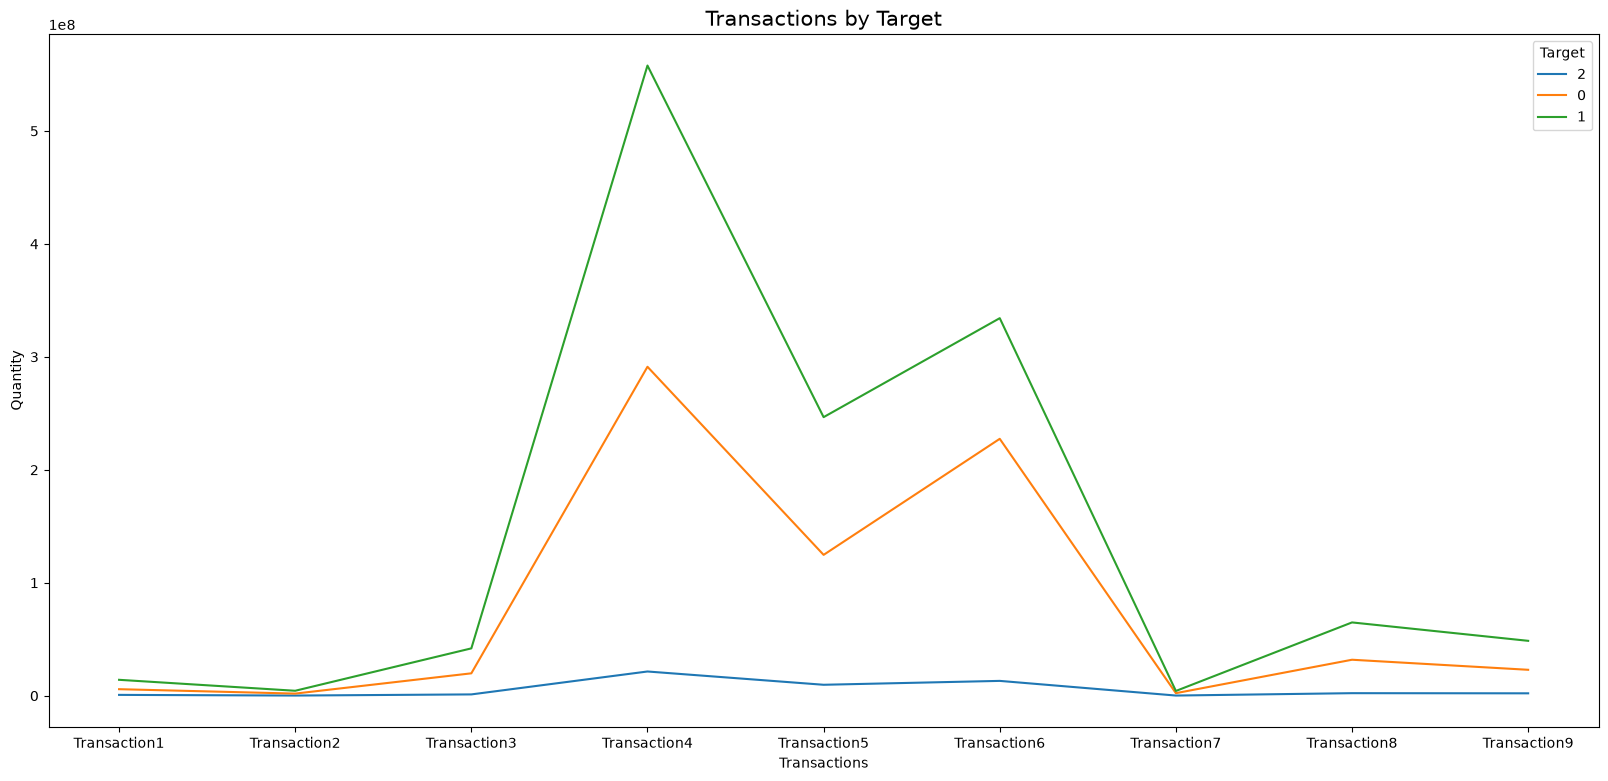

In [52]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("Transactions by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [53]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]].sum()

In [54]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Target
0,0,271,238,2,121,24,57,2


In [55]:
group_train_campaign_result

,Target,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6
0,0,0,7035,3869,39,2656,564,1175
1,0,1,7,25,0,8,1,1
2,1,0,5781,6342,74,3230,848,1501
3,1,1,5,31,0,4,3,3
4,1,2,0,2,0,0,0,0


In [56]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [57]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

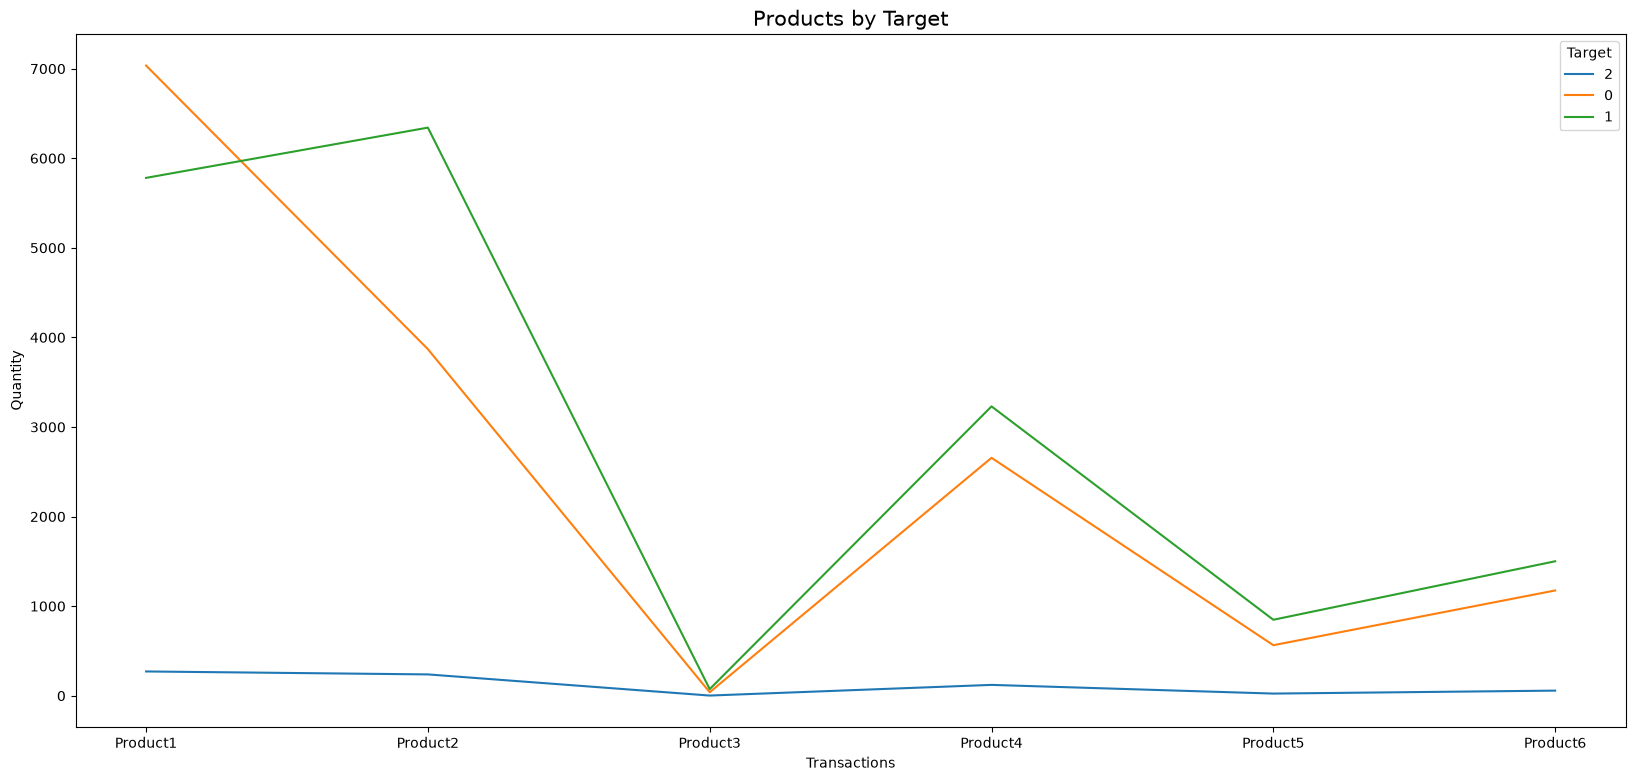

In [58]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("Products by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [59]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[
    [
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
    ]
].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[
    [
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
    ]
].sum()

In [60]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,Target
0,0,316,436,119,193,272,143,31,2


In [61]:
group_train_campaign_result

,Target,PreviousCampaignResult,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7
0,0,0,6310,9427,2677,3859,5783,3222,523
1,0,1,11,16,4,4,21,2,1
2,1,0,6278,9854,2597,4053,6461,3201,711
3,1,1,10,23,4,6,14,2,1
4,1,2,1,2,0,0,0,0,0


In [62]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [63]:
group_campaign_result

,PreviousCampaignResult,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,Target
0,0,316,436,119,193,272,143,31,2
0,0,6310,9427,2677,3859,5783,3222,523,0
1,1,11,16,4,4,21,2,1,0
2,0,6278,9854,2597,4053,6461,3201,711,1
3,1,10,23,4,6,14,2,1,1
4,2,1,2,0,0,0,0,0,1


In [64]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

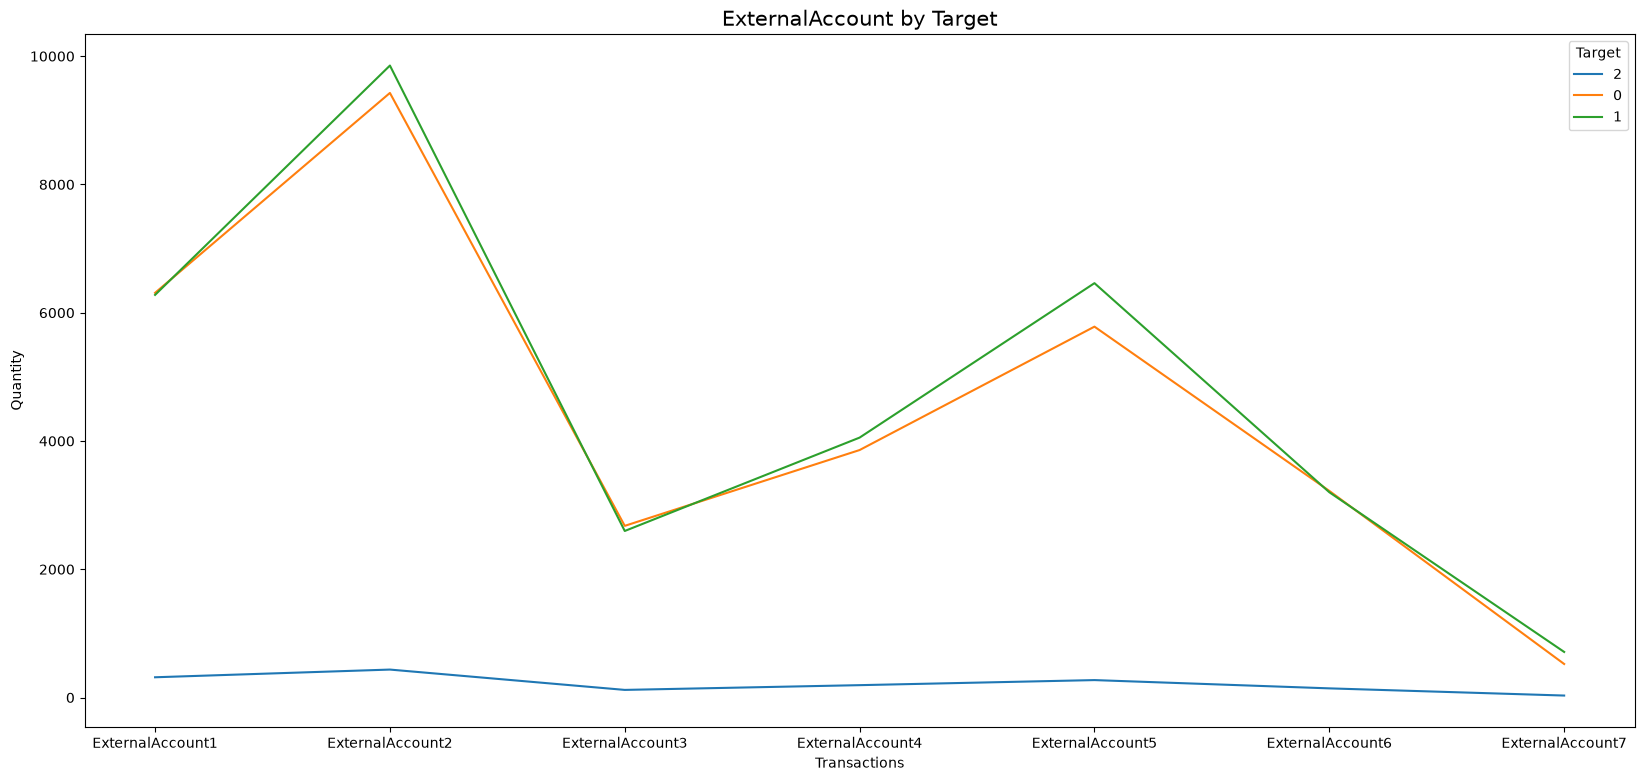

In [65]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("ExternalAccount by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [66]:
group_train_campaign_result = df_train[df_train["PreviousCampaignResult"] == 0][
    ["ActivityIndicator", "Target"]
]

In [67]:
group_test_campaign_result = df_test[df_test["PreviousCampaignResult"] == 0][
    ["ActivityIndicator"]
]
group_test_campaign_result["Target"] = 2

In [68]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [69]:
group_campaign_result

,ActivityIndicator,Target
0,0,2
1,0,2
2,0,2
3,0,2
4,10,2
...,...,...
63994,4,0
63995,0,0
63996,0,1
63997,2,0


In [70]:
group_campaign_result = group_campaign_result.groupby(by=["Target"], as_index=False)[
    ["ActivityIndicator"]
].sum()

In [71]:
group_campaign_result

,Target,ActivityIndicator
0,0,425139
1,1,828905
2,2,29431


In [72]:
group_campaign_result["Percentage"] = 0.0

In [73]:
group_campaign_result.loc[
    group_campaign_result["Target"].isin([0, 1]), "Percentage"
] = (
            group_campaign_result[group_campaign_result["Target"].isin([0, 1])][
                "ActivityIndicator"
            ]
            / group_campaign_result[group_campaign_result["Target"].isin([0, 1])][
                "ActivityIndicator"
            ].sum()
    ) * 100

In [74]:
group_campaign_result.loc[group_campaign_result["Target"] == 2, "Percentage"] = (
                                                                                        group_campaign_result[
                                                                                            group_campaign_result[
                                                                                                "Target"] == 2][
                                                                                            "ActivityIndicator"]
                                                                                        / group_campaign_result[
                                                                                            group_campaign_result[
                                                                                                "Target"] == 2][
                                                                                            "ActivityIndicator"
                                                                                        ].sum()
                                                                                ) * 100

In [75]:
group_campaign_result

,Target,ActivityIndicator,Percentage
0,0,425139,33.901442
1,1,828905,66.098558
2,2,29431,100.000000


In [76]:
group_campaign_result.set_index("Target", inplace=True)

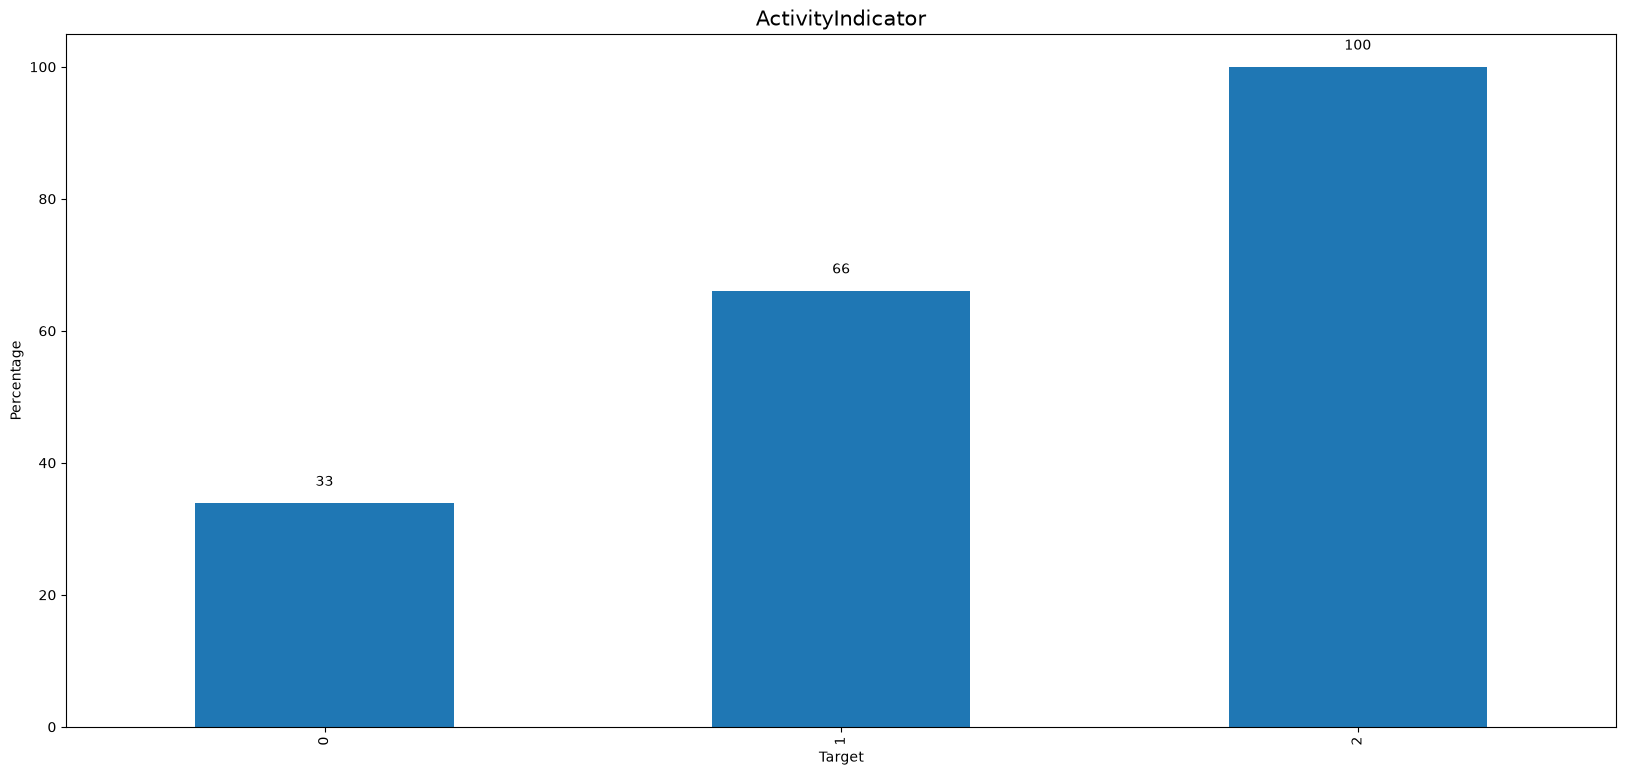

In [77]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
group_campaign_result["Percentage"].plot(kind="bar", ax=ax)
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.xlabel("Target")
plt.ylabel("Percentage")
plt.title("ActivityIndicator", fontsize=15).set_position([0.5, 1.05])

plt.show()

In [78]:
group_train_campaign_result = df_train.groupby(
    by=["Target", "RegularInteractionIndicator"], as_index=False
).agg(Total=("RegularInteractionIndicator", "sum"))

In [79]:
group_test_campaign_result = df_test.groupby(
    by=["RegularInteractionIndicator"], as_index=False
).agg(Total=("RegularInteractionIndicator", "sum"))
group_test_campaign_result["Target"] = 2

In [80]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [81]:
group_campaign_result

,RegularInteractionIndicator,Total,Target
0,0,0,2
1,1,385,2
2,2,220,2
3,3,90,2
4,4,68,2
5,5,65,2
6,6,24,2
7,9,9,2
8,15,15,2
0,0,0,0


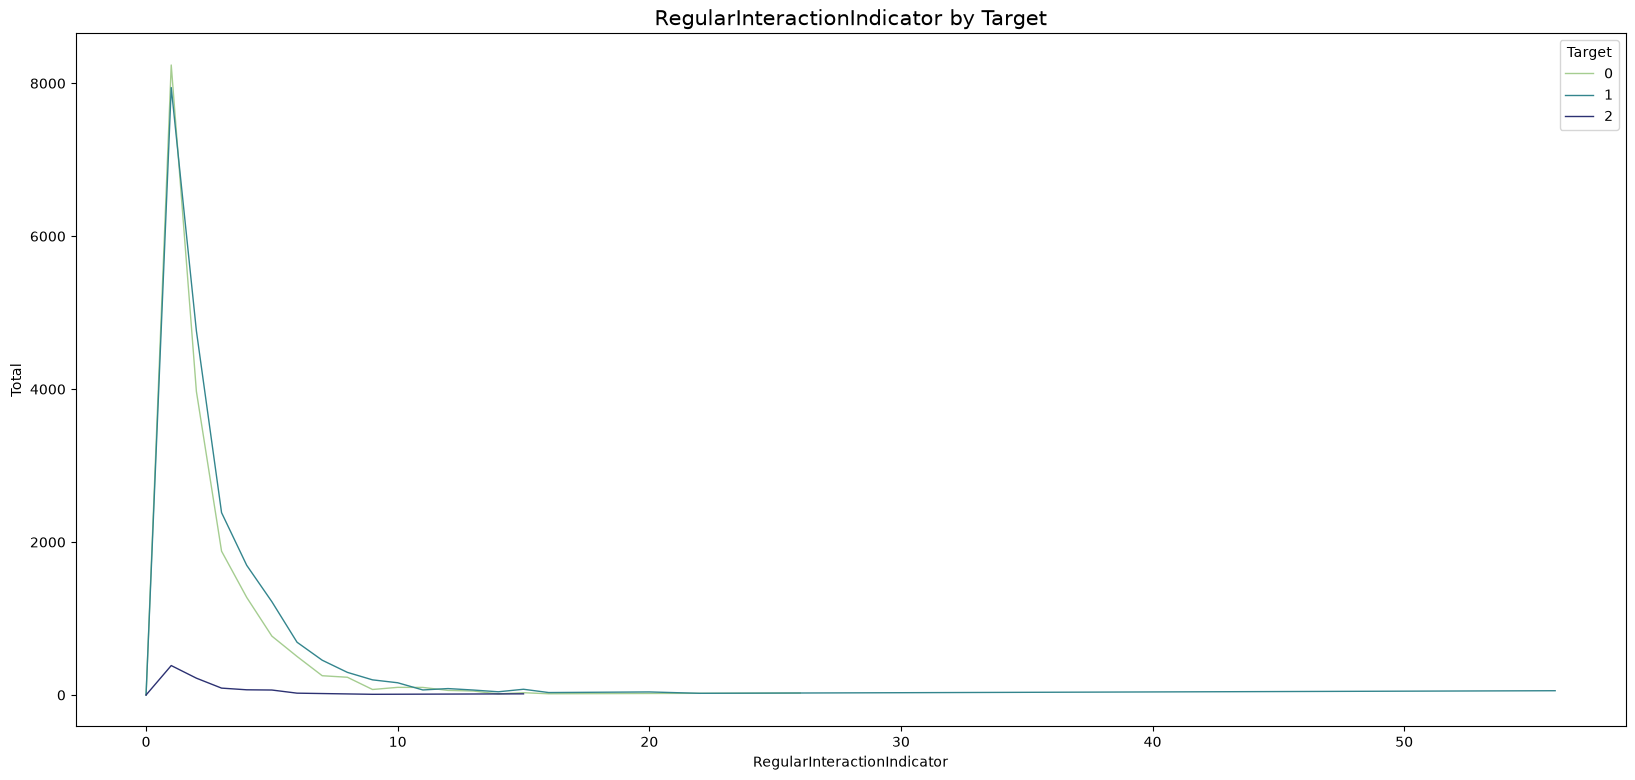

In [82]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x=group_campaign_result["RegularInteractionIndicator"],
    y=group_campaign_result["Total"],
    hue=group_campaign_result["Target"],
    palette=sns.color_palette("crest", as_cmap=True),
    estimator=None,
    lw=1,
    markers=True,
    ax=ax,
)
plt.xlabel("RegularInteractionIndicator")
plt.ylabel("Total")
plt.title("RegularInteractionIndicator by Target", fontsize=15)

plt.legend(title="Target")
plt.show()

In [83]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[
    [
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
    ]
].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[
    [
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
    ]
].sum()

In [84]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,Target
0,0,2036.5,2715.95,2053.5,2601.0,2805.8,2477.75,2137.6,2


In [85]:
group_train_campaign_result

,Target,PreviousCampaignResult,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7
0,0,0,44073.200,58681.100,44467.350,56247.100,60086.350,53635.900,45139.000
1,0,1,63.250,80.600,63.450,74.200,83.700,76.000,55.250
2,1,0,44097.550,58681.800,44472.600,56058.850,60237.200,53623.400,45123.150
3,1,1,65.225,83.125,65.925,82.925,83.625,79.625,60.475
4,1,2,2.500,3.350,2.550,3.800,3.550,3.150,3.600


In [86]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [87]:
group_campaign_result

,PreviousCampaignResult,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,Target
0,0,2036.500,2715.950,2053.500,2601.000,2805.800,2477.750,2137.600,2
0,0,44073.200,58681.100,44467.350,56247.100,60086.350,53635.900,45139.000,0
1,1,63.250,80.600,63.450,74.200,83.700,76.000,55.250,0
2,0,44097.550,58681.800,44472.600,56058.850,60237.200,53623.400,45123.150,1
3,1,65.225,83.125,65.925,82.925,83.625,79.625,60.475,1
4,2,2.500,3.350,2.550,3.800,3.550,3.150,3.600,1


In [88]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

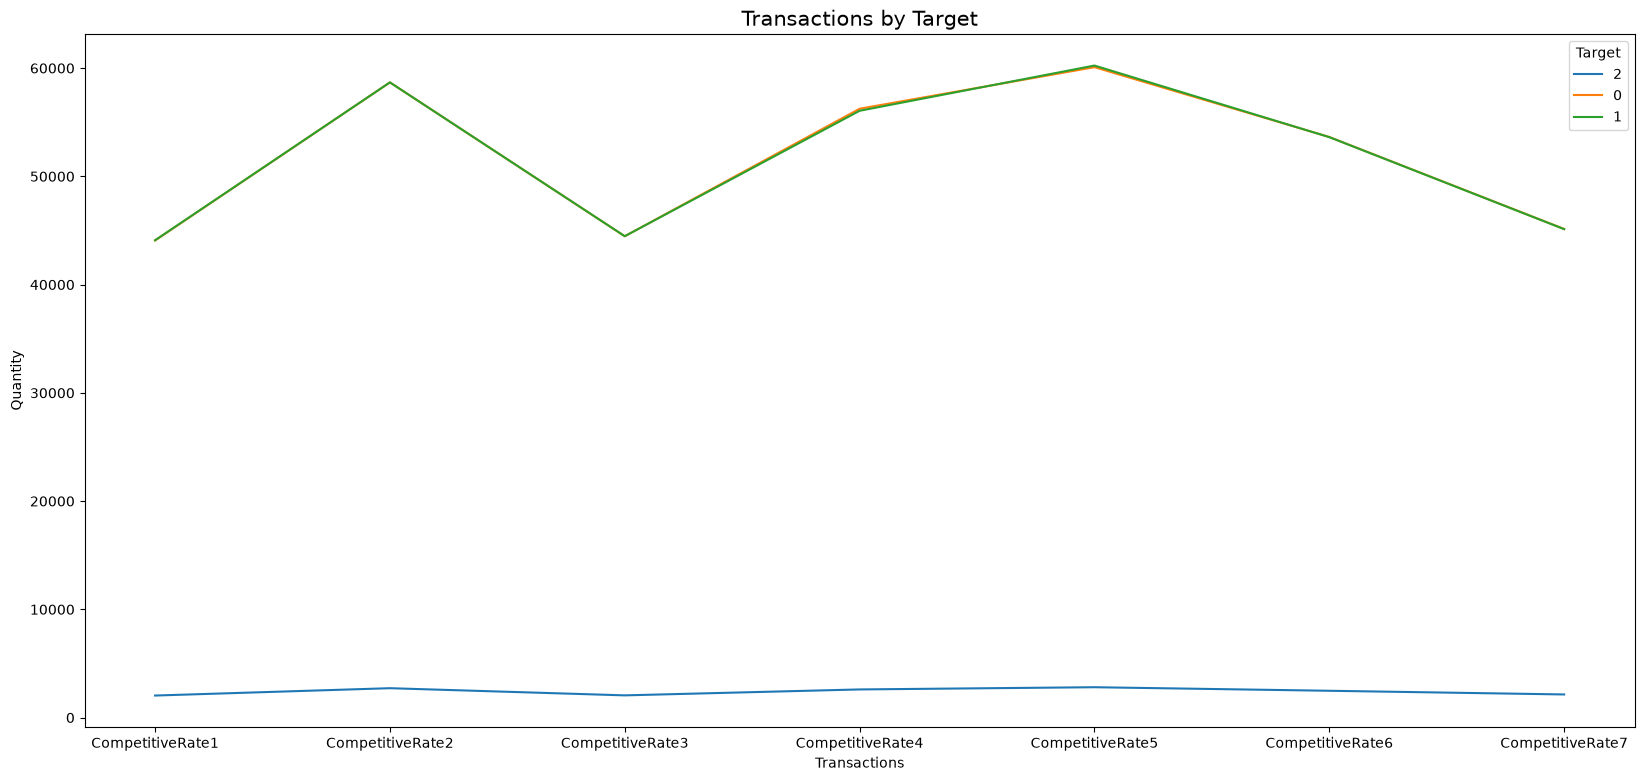

In [89]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("Transactions by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [90]:
# df_graph = df_train[df_train["PreviousCampaignResult"] == 0][["RateBefore", "Product1", "Product2", "Product3", "Product4", "Product5", "Product6", "Target"]].groupby(by=["Target"], as_index=False).sum().set_index('Target').rename(index = {0:'Total'}).T

In [91]:
group_train_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "RateBefore",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "Target",
        ]
    ]
    .groupby(by=["Target"], as_index=False)
    .sum()
)

In [92]:
group_train_campaign_result["%Product1"] = 0.0
group_train_campaign_result["%Product2"] = 0.0
group_train_campaign_result["%Product3"] = 0.0
group_train_campaign_result["%Product4"] = 0.0
group_train_campaign_result["%Product5"] = 0.0
group_train_campaign_result["%Product6"] = 0.0

In [93]:
group_train_campaign_result.loc[:, "Total"] = (
        group_train_campaign_result["Product1"]
        + group_train_campaign_result["Product2"]
        + group_train_campaign_result["Product3"]
        + group_train_campaign_result["Product4"]
        + group_train_campaign_result["Product5"]
        + group_train_campaign_result["Product6"]
)

In [94]:
group_train_campaign_result.loc[:, "%Product1"] = (
                                                          group_train_campaign_result["Product1"] *
                                                          group_train_campaign_result["RateBefore"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product2"] = (
                                                          group_train_campaign_result["Product2"] *
                                                          group_train_campaign_result["RateBefore"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product3"] = (
                                                          group_train_campaign_result["Product3"] *
                                                          group_train_campaign_result["RateBefore"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product4"] = (
                                                          group_train_campaign_result["Product4"] *
                                                          group_train_campaign_result["RateBefore"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product5"] = (
                                                          group_train_campaign_result["Product5"] *
                                                          group_train_campaign_result["RateBefore"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product6"] = (
                                                          group_train_campaign_result["Product6"] *
                                                          group_train_campaign_result["RateBefore"]
                                                  ) / group_train_campaign_result["Total"]

In [95]:
group_train_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "RateBefore",
        "Total",
    ],
    inplace=True,
)

In [96]:
group_train_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,0,24600.896890,13529.619057,136.380239,9287.843943,1972.268066,4108.891805
1,1,17439.068148,19131.390797,223.229725,9743.675855,2558.091989,4527.943486


In [97]:
group_test_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "RateBefore",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "PreviousCampaignResult",
        ]
    ]
    .groupby(by=["PreviousCampaignResult"], as_index=False)
    .sum()
)

In [98]:
group_test_campaign_result.rename(
    columns={"PreviousCampaignResult": "Target"}, inplace=True
)

In [99]:
group_test_campaign_result["Target"] = 2

In [100]:
group_test_campaign_result["%Product1"] = 0.0
group_test_campaign_result["%Product2"] = 0.0
group_test_campaign_result["%Product3"] = 0.0
group_test_campaign_result["%Product4"] = 0.0
group_test_campaign_result["%Product5"] = 0.0
group_test_campaign_result["%Product6"] = 0.0

In [101]:
group_test_campaign_result.loc[:, "Total"] = (
        group_test_campaign_result["Product1"]
        + group_test_campaign_result["Product2"]
        + group_test_campaign_result["Product3"]
        + group_test_campaign_result["Product4"]
        + group_test_campaign_result["Product5"]
        + group_test_campaign_result["Product6"]
)

In [102]:
group_test_campaign_result.loc[:, "%Product1"] = (
                                                         group_test_campaign_result["Product1"] *
                                                         group_test_campaign_result["RateBefore"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product2"] = (
                                                         group_test_campaign_result["Product2"] *
                                                         group_test_campaign_result["RateBefore"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product3"] = (
                                                         group_test_campaign_result["Product3"] *
                                                         group_test_campaign_result["RateBefore"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product4"] = (
                                                         group_test_campaign_result["Product4"] *
                                                         group_test_campaign_result["RateBefore"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product5"] = (
                                                         group_test_campaign_result["Product5"] *
                                                         group_test_campaign_result["RateBefore"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product6"] = (
                                                         group_test_campaign_result["Product6"] *
                                                         group_test_campaign_result["RateBefore"]
                                                 ) / group_test_campaign_result["Total"]

In [103]:
group_test_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "RateBefore",
        "Total",
    ],
    inplace=True,
)

In [104]:
group_test_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,2,41512.205979,33074.370728,366.017422,19065.296847,4573.598224,8667.810799


In [105]:
group_campaign_result = pd.concat(
    [group_train_campaign_result, group_test_campaign_result]
)

In [106]:
group_campaign_result_rate_before = group_campaign_result.set_index(
    "Target"
).transpose()

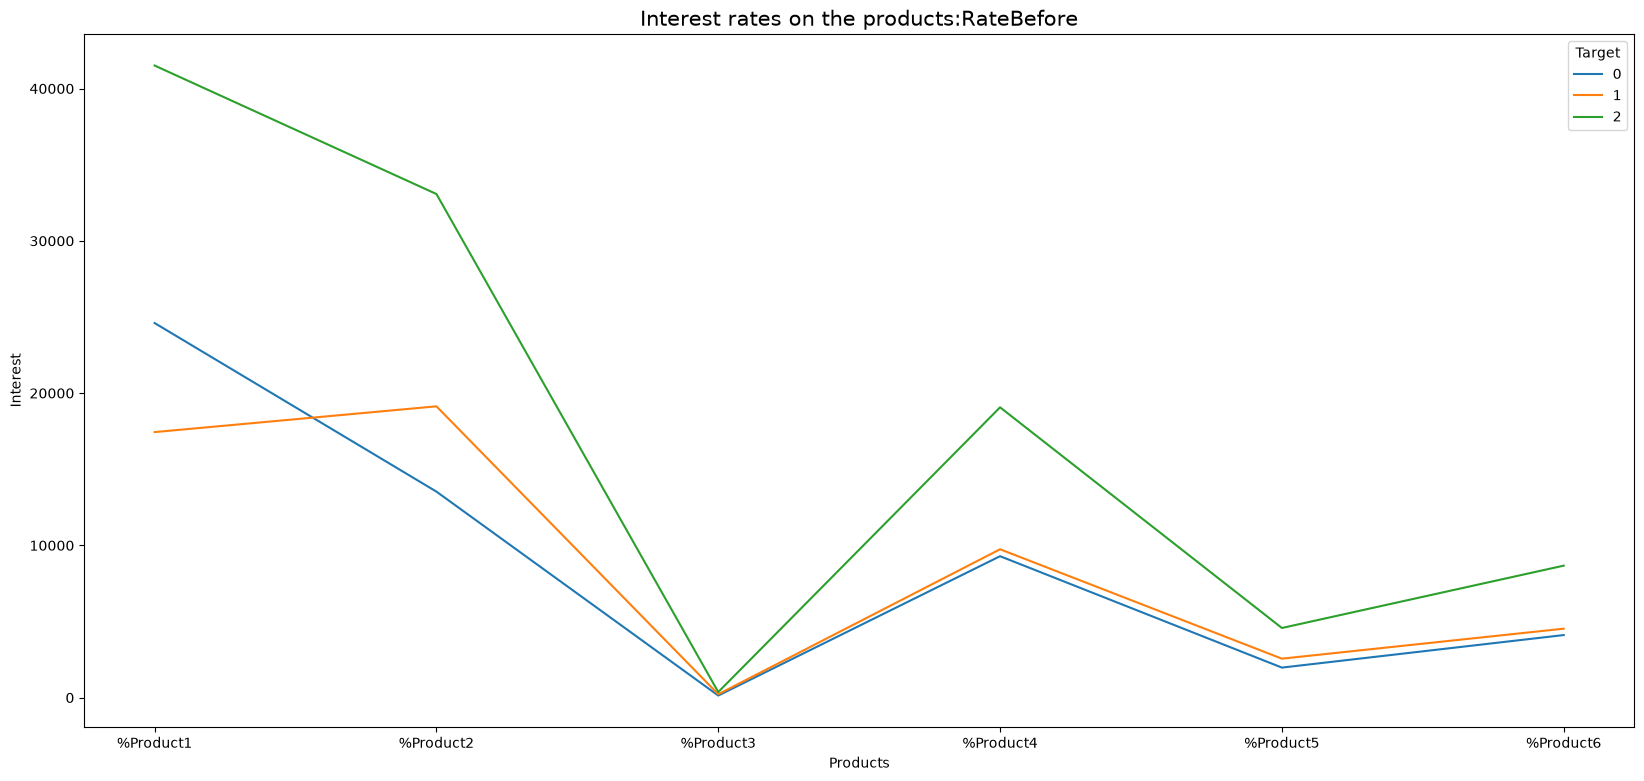

In [107]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Products")
plt.ylabel("Interest")
plt.title("Interest rates on the products:RateBefore", fontsize=15).set_position(
    [0.5, 1.05]
)
group_campaign_result_rate_before.plot(ax=ax)
plt.show()

In [108]:
group_train_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "ReferenceRate",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "Target",
        ]
    ]
    .groupby(by=["Target"], as_index=False)
    .sum()
)

In [109]:
group_train_campaign_result["%Product1"] = 0.0
group_train_campaign_result["%Product2"] = 0.0
group_train_campaign_result["%Product3"] = 0.0
group_train_campaign_result["%Product4"] = 0.0
group_train_campaign_result["%Product5"] = 0.0
group_train_campaign_result["%Product6"] = 0.0

In [110]:
group_train_campaign_result.loc[:, "Total"] = (
        group_train_campaign_result["Product1"]
        + group_train_campaign_result["Product2"]
        + group_train_campaign_result["Product3"]
        + group_train_campaign_result["Product4"]
        + group_train_campaign_result["Product5"]
        + group_train_campaign_result["Product6"]
)

In [111]:
group_train_campaign_result.loc[:, "%Product1"] = (
                                                          group_train_campaign_result["Product1"]
                                                          * group_train_campaign_result["ReferenceRate"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product2"] = (
                                                          group_train_campaign_result["Product2"]
                                                          * group_train_campaign_result["ReferenceRate"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product3"] = (
                                                          group_train_campaign_result["Product3"]
                                                          * group_train_campaign_result["ReferenceRate"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product4"] = (
                                                          group_train_campaign_result["Product4"]
                                                          * group_train_campaign_result["ReferenceRate"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product5"] = (
                                                          group_train_campaign_result["Product5"]
                                                          * group_train_campaign_result["ReferenceRate"]
                                                  ) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product6"] = (
                                                          group_train_campaign_result["Product6"]
                                                          * group_train_campaign_result["ReferenceRate"]
                                                  ) / group_train_campaign_result["Total"]

In [112]:
group_train_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "ReferenceRate",
        "Total",
    ],
    inplace=True,
)

In [113]:
group_train_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,0,19275.500962,10600.840543,106.857788,7277.289347,1545.328009,3219.433352
1,1,13667.027439,14993.303583,174.945516,7636.135379,2004.781053,3548.557029


In [114]:
group_test_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "ReferenceRate",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "PreviousCampaignResult",
        ]
    ]
    .groupby(by=["PreviousCampaignResult"], as_index=False)
    .sum()
)

In [115]:
group_test_campaign_result.rename(
    columns={"PreviousCampaignResult": "Target"}, inplace=True
)

In [116]:
group_test_campaign_result["Target"] = 2

In [117]:
group_test_campaign_result["%Product1"] = 0.0
group_test_campaign_result["%Product2"] = 0.0
group_test_campaign_result["%Product3"] = 0.0
group_test_campaign_result["%Product4"] = 0.0
group_test_campaign_result["%Product5"] = 0.0
group_test_campaign_result["%Product6"] = 0.0

In [118]:
group_test_campaign_result.loc[:, "Total"] = (
        group_test_campaign_result["Product1"]
        + group_test_campaign_result["Product2"]
        + group_test_campaign_result["Product3"]
        + group_test_campaign_result["Product4"]
        + group_test_campaign_result["Product5"]
        + group_test_campaign_result["Product6"]
)

In [119]:
group_test_campaign_result.loc[:, "%Product1"] = (
                                                         group_test_campaign_result["Product1"] *
                                                         group_test_campaign_result["ReferenceRate"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product2"] = (
                                                         group_test_campaign_result["Product2"] *
                                                         group_test_campaign_result["ReferenceRate"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product3"] = (
                                                         group_test_campaign_result["Product3"] *
                                                         group_test_campaign_result["ReferenceRate"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product4"] = (
                                                         group_test_campaign_result["Product4"] *
                                                         group_test_campaign_result["ReferenceRate"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product5"] = (
                                                         group_test_campaign_result["Product5"] *
                                                         group_test_campaign_result["ReferenceRate"]
                                                 ) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product6"] = (
                                                         group_test_campaign_result["Product6"] *
                                                         group_test_campaign_result["ReferenceRate"]
                                                 ) / group_test_campaign_result["Total"]

In [120]:
group_test_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "ReferenceRate",
        "Total",
    ],
    inplace=True,
)

In [121]:
group_test_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,2,32529.588694,25917.574138,286.816754,14939.853234,3583.940327,6792.226853


In [122]:
group_campaign_result = pd.concat(
    [group_train_campaign_result, group_test_campaign_result]
)

In [123]:
group_campaign_result_reference_rate = group_campaign_result.set_index(
    "Target"
).transpose()

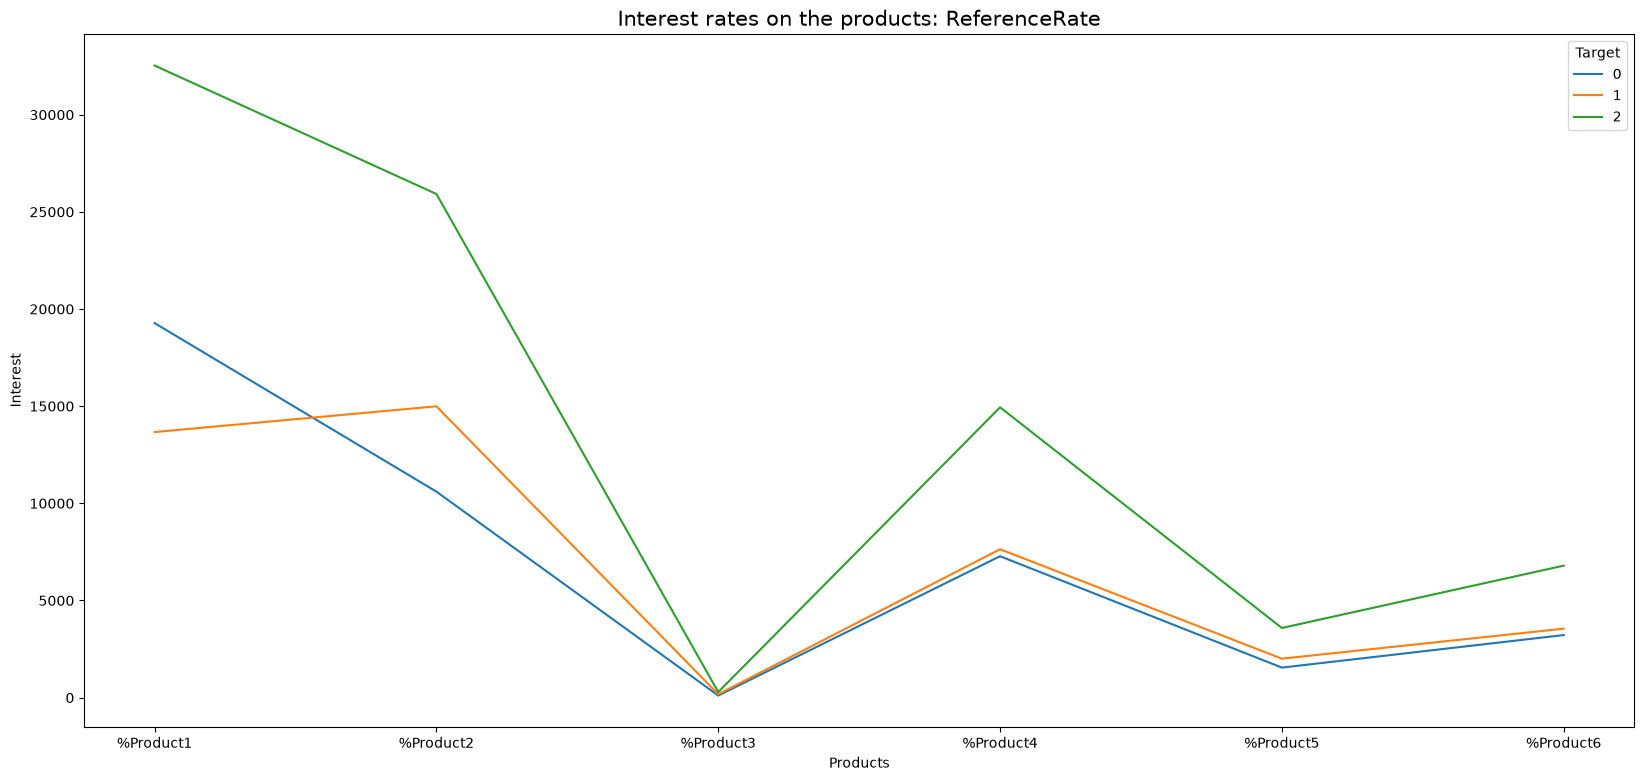

In [124]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Products")
plt.ylabel("Interest")
plt.title("Interest rates on the products: ReferenceRate", fontsize=15).set_position(
    [0.5, 1.05]
)
group_campaign_result_reference_rate.plot(ax=ax)
plt.show()

In [125]:
group_campaign_result_reference_rate = group_campaign_result_reference_rate.T

In [126]:
group_campaign_result_reference_rate

,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
Target,,,,,,
0,19275.500962,10600.840543,106.857788,7277.289347,1545.328009,3219.433352
1,13667.027439,14993.303583,174.945516,7636.135379,2004.781053,3548.557029
2,32529.588694,25917.574138,286.816754,14939.853234,3583.940327,6792.226853


In [127]:
group_campaign_result_reference_rate.loc[
    group_campaign_result_reference_rate.index == 0, "Target"
] = "reference_rate_0"
group_campaign_result_reference_rate.loc[
    group_campaign_result_reference_rate.index == 1, "Target"
] = "reference_rate_1"
group_campaign_result_reference_rate.loc[
    group_campaign_result_reference_rate.index == 2, "Target"
] = "reference_rate_2"

In [128]:
group_campaign_result_reference_rate.set_index("Target", inplace=True)

In [129]:
group_campaign_result_rate_before = group_campaign_result_rate_before.T

In [130]:
group_campaign_result_rate_before

,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
Target,,,,,,
0,24600.896890,13529.619057,136.380239,9287.843943,1972.268066,4108.891805
1,17439.068148,19131.390797,223.229725,9743.675855,2558.091989,4527.943486
2,41512.205979,33074.370728,366.017422,19065.296847,4573.598224,8667.810799


In [131]:
group_campaign_result_rate_before.loc[
    group_campaign_result_rate_before.index == 0, "Target"
] = "rate_before_0"
group_campaign_result_rate_before.loc[
    group_campaign_result_rate_before.index == 1, "Target"
] = "rate_before_1"
group_campaign_result_rate_before.loc[
    group_campaign_result_rate_before.index == 2, "Target"
] = "rate_before_2"

In [132]:
group_campaign_result_rate_before.set_index("Target", inplace=True)

In [133]:
group_campaign_result_total = pd.concat(
    [group_campaign_result_rate_before, group_campaign_result_reference_rate]
)

In [134]:
group_campaign_result_total

,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
Target,,,,,,
rate_before_0,24600.896890,13529.619057,136.380239,9287.843943,1972.268066,4108.891805
rate_before_1,17439.068148,19131.390797,223.229725,9743.675855,2558.091989,4527.943486
rate_before_2,41512.205979,33074.370728,366.017422,19065.296847,4573.598224,8667.810799
reference_rate_0,19275.500962,10600.840543,106.857788,7277.289347,1545.328009,3219.433352
reference_rate_1,13667.027439,14993.303583,174.945516,7636.135379,2004.781053,3548.557029
reference_rate_2,32529.588694,25917.574138,286.816754,14939.853234,3583.940327,6792.226853


In [135]:
group_campaign_result_total = group_campaign_result_total.T

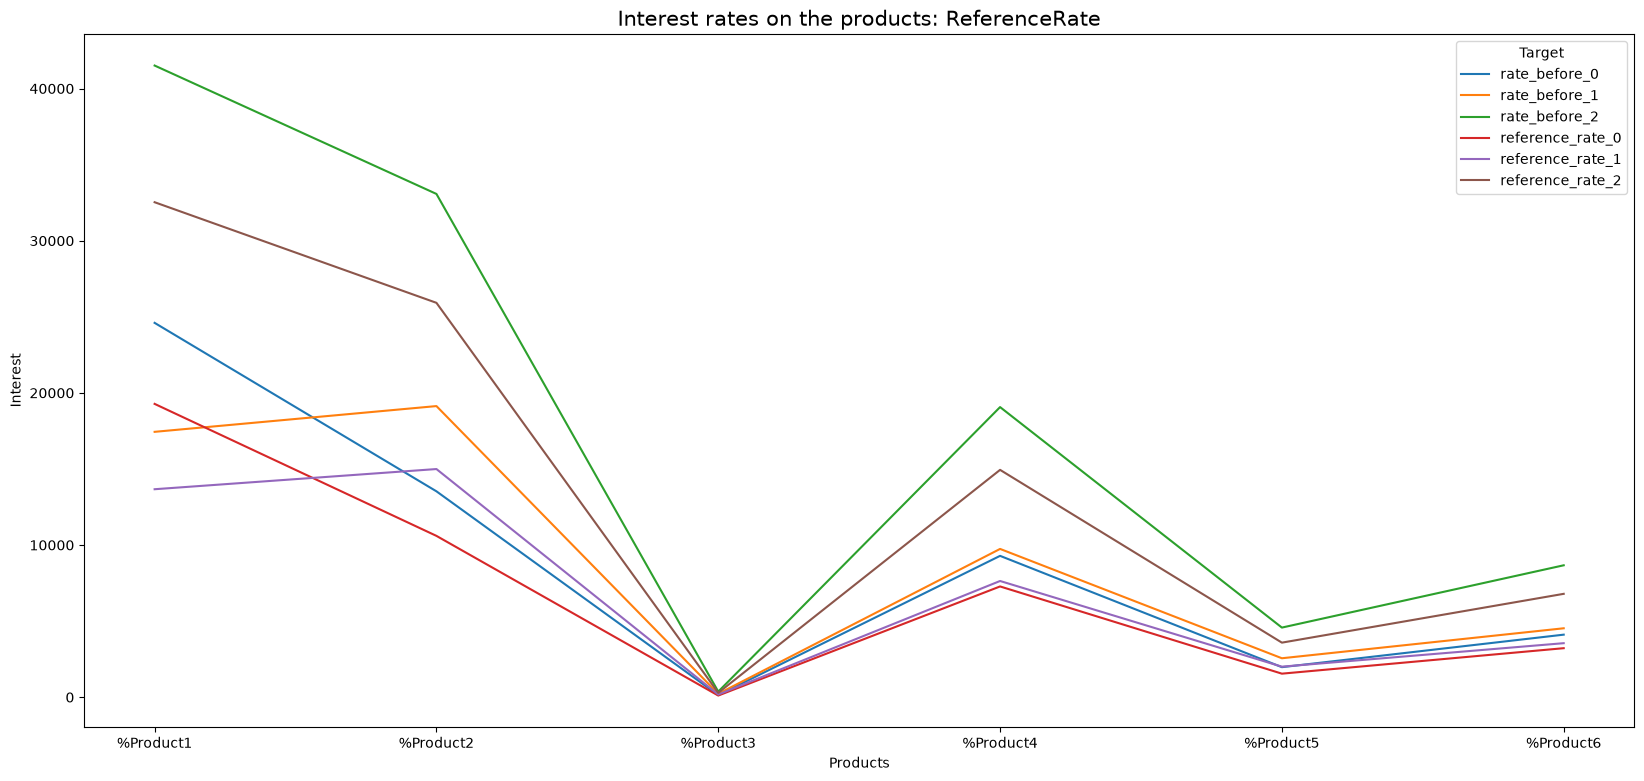

In [136]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Products")
plt.ylabel("Interest")
plt.title("Interest rates on the products: ReferenceRate", fontsize=15).set_position(
    [0.5, 1.05]
)
group_campaign_result_total.plot(ax=ax)
plt.show()

In [137]:
del group_campaign_result_total
del group_campaign_result_rate_before
del group_campaign_result_reference_rate

In [138]:
df_train[
    [
        "Balance",
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
        "Target",
    ]
]

,Balance,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,Target
0,43824.59,0.00,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0
1,11256.21,0.00,0.00,0.0,8525.0,0.00,0.00,0.0,0.0,0.0,1
2,18795.11,13422.35,800.00,0.0,0.0,0.00,13123.28,0.0,0.0,0.0,1
3,22274.72,0.00,0.00,0.0,1000.0,23900.00,0.00,0.0,0.0,0.0,0
4,47923.40,0.00,0.00,0.0,0.0,2000.00,27629.11,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...
63994,40444.92,0.00,747.18,0.0,0.0,11496.44,22242.00,0.0,0.0,0.0,0
63995,47395.91,0.00,0.00,0.0,300.0,0.00,0.00,0.0,0.0,0.0,0
63996,10086.31,0.00,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.0,1
63997,26452.64,0.00,0.00,0.0,14300.0,0.00,0.00,0.0,0.0,0.0,0


In [139]:
df_train[
    (df_train["Transaction1"] == 0)
    & (df_train["Transaction2"] == 0)
    & (df_train["Transaction3"] == 0)
    & (df_train["Transaction4"] == 0)
    & (df_train["Transaction5"] == 0)
    & (df_train["Transaction6"] == 0)
    & (df_train["Transaction7"] == 0)
    & (df_train["Transaction8"] == 0)
    & (df_train["Transaction9"] == 0)
    & (df_train["Target"] == 1)
    & (df_train["PreviousCampaignResult"] == 0)
    ][
    [
        "Customer_id",
        "Balance",
        "PreviousCampaignResult",
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
        "ActivityIndicator",
        "RegularInteractionIndicator",
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
        "RateBefore",
        "ReferenceRate",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Balance,4165.0,22144.467450,10795.166343,10000.000,13063.480,19150.670,29145.560,49999.550
PreviousCampaignResult,4165.0,0.000000,0.000000,0.000,0.000,0.000,0.000,0.000
Product1,4165.0,0.127011,0.333025,0.000,0.000,0.000,0.000,1.000
Product2,4165.0,0.029772,0.169978,0.000,0.000,0.000,0.000,1.000
Product3,4165.0,0.000000,0.000000,0.000,0.000,0.000,0.000,0.000
Product4,4165.0,0.036255,0.186945,0.000,0.000,0.000,0.000,1.000
Product5,4165.0,0.012245,0.109990,0.000,0.000,0.000,0.000,1.000
Product6,4165.0,0.024250,0.153842,0.000,0.000,0.000,0.000,1.000
ExternalAccount1,4165.0,0.194478,0.395846,0.000,0.000,0.000,0.000,1.000
ExternalAccount2,4165.0,0.285954,0.451922,0.000,0.000,0.000,1.000,1.000


In [140]:
df_train[
    df_train.loc[:, ~df_train.columns.isin(["Target", "Customer_id"])].duplicated(
        keep=False
    )
]

,Customer_id,Target,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate,TotalProducts,CountNegativeTransactions,CountPositiveTransactions,CountTransactions,AverageTransactions,AverageInterestRate,TotalExternalAccount,TotalAverageInterest,TotalAverageInterestBalance
18489,CTSP018490,1,11143.58,0,0,1,0,0,0,0,0.0,0.0,0.0,10000.0,0.0,525.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,1,0,2,2,1169.444444,1.467857,1,17.165774,153.224225
53008,CTSP053009,1,11143.58,0,0,1,0,0,0,0,0.0,0.0,0.0,10000.0,0.0,525.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,1,0,2,2,1169.444444,1.467857,1,17.165774,153.224225


# MODELS

In [141]:
# Attempt 1
# train = df_train.drop(columns=["Customer_id", "Balance", "Product1", "Product2", "Product3", "Product4", "Product5", "Product6", "Transaction1", "Transaction2", "Transaction3", "Transaction4", "Transaction5", "Transaction6", "Transaction7", "Transaction8", "Transaction9", "ExternalAccount1", "ExternalAccount2", "ExternalAccount3", "ExternalAccount4", "ExternalAccount5", "ExternalAccount6", "ExternalAccount7", "CompetitiveRate1", "CompetitiveRate2", "CompetitiveRate3", "CompetitiveRate4", "CompetitiveRate5", "CompetitiveRate6", "CompetitiveRate7", "RateBefore"])

In [142]:
# Attempt 2
# train = df_train.drop(columns=["Customer_id", "TotalProducts","Transaction1", "Transaction2", "Transaction3", "Transaction4", "Transaction5", "Transaction6", "Transaction7", "Transaction8", "Transaction9", "CompetitiveRate1", "CompetitiveRate2", "CompetitiveRate3", "CompetitiveRate4", "CompetitiveRate5", "CompetitiveRate6", "CompetitiveRate7", "TotalExternalAccount", "TotalAverageInterest", "TotalAverageInterestBalance"])

In [143]:
# Attempt 3
# train = df_train.drop(columns=["Customer_id"])

In [144]:
# Attempt 4
# train = df_train.drop(columns=["Customer_id"])
# train = pd.get_dummies(train, columns=['PreviousCampaignResult'])
# test = pd.get_dummies(df_test, columns=['PreviousCampaignResult'])
# test["PreviousCampaignResult_1"] = 0
# test["PreviousCampaignResult_2"] = 0

In [145]:
# Attempt 5
# train = df_train.drop(columns=["Customer_id"])
# train = pd.get_dummies(train, columns=['PreviousCampaignResult', 'ActivityIndicator', 'RegularInteractionIndicator'])
# test = pd.get_dummies(df_test, columns=['PreviousCampaignResult', 'ActivityIndicator', 'RegularInteractionIndicator'])
# test["PreviousCampaignResult_1"] = 0
# test["PreviousCampaignResult_2"] = 0

In [146]:
# Attempt 6
train = df_train_cleaned.drop(
    columns=[
        "Customer_id",
        "TotalAverageInterestBalance",
        "TotalAverageInterest",
        "RateBefore",
        "AverageTransactions",
        "AverageInterestRate",
    ]
)
train = pd.get_dummies(
    train,
    columns=[
        "ActivityIndicator",
        # "PreviousCampaignResult",
        "RegularInteractionIndicator",
    ],
)
test = pd.get_dummies(
    df_test,
    columns=[
        "ActivityIndicator",
        # "PreviousCampaignResult",
        "RegularInteractionIndicator",
    ],
)

In [147]:
scaler_columns = [
    "Balance",
    "Transaction1",
    "Transaction2",
    "Transaction3",
    "Transaction4",
    "Transaction5",
    "Transaction6",
    "Transaction7",
    "Transaction8",
    "Transaction9",
    "CompetitiveRate1",
    "CompetitiveRate2",
    "CompetitiveRate3",
    "CompetitiveRate4",
    "CompetitiveRate5",
    "CompetitiveRate6",
    "CompetitiveRate7",
    # "RateBefore",
    "ReferenceRate",
    # "AverageTransactions",
    # "AverageInterestRate",
]
scaler = StandardScaler()
train[scaler_columns] = scaler.fit_transform(train[scaler_columns])
scaler_test = StandardScaler()
test[scaler_columns] = scaler_test.fit_transform(test[scaler_columns])

In [148]:
train.drop_duplicates(inplace=True)

In [149]:
X_train_md = train.drop(["Target"], axis=1)  # Features
y_train_md = train["Target"]  # Target variable
X_test_md = test.loc[:, test.columns.isin(X_train_md.columns)]
random_state = 42  # 42
test_size = 0.2

In [150]:
X = X_train_md  # Features
y = y_train_md  # Target variable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=random_state
)

In [151]:
def get_metrics(model: object, text_model: str, y_test, y_pred, X_train, y_train):
    print(f"---{text_model}---")
    print(f"{text_model} Accuracy: %.3f" % (accuracy_score(y_test, y_pred) * 100))
    print(f"{text_model} Precision: %.3f" % (precision_score(y_test, y_pred) * 100))
    print(f"{text_model} Recall: %.3f" % (recall_score(y_test, y_pred) * 100))
    print(f"{text_model} F1 score: %.3f" % (f1_score(y_test, y_pred) * 100))
    print(f"{text_model} r2_score:  %.3f" % r2_score(y_test, y_pred))

    print("\n--------")
    print("Training Set")
    print(
        f"Accuracy of {text_model} on training set: %.3f"
        % (model.score(X_train, y_train) * 100)
    )
    print("Test Set")
    print(
        f"Accuracy of {text_model} on training set: %.3f"
        % (model.score(X_test, y_test) * 100)
    )

In [152]:
# Logistic Regression
logr = LogisticRegression(random_state=42)

param_grid = {"C": [4, 0.01, 0.1, 1]}
grid_search = GridSearchCV(logr, param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

logr = LogisticRegression(C=grid_search.best_params_["C"], random_state=42)
logr.fit(X_train, y_train)
logr_y_pred = logr.predict(X_test)
get_metrics(logr, "LogisticRegression", y_test, logr_y_pred, X_train, y_train)

---LogisticRegression---
LogisticRegression Accuracy: 60.726
LogisticRegression Precision: 59.746
LogisticRegression Recall: 51.989
LogisticRegression F1 score: 55.598
LogisticRegression r2_score:  -0.576

--------
Training Set


Accuracy of LogisticRegression on training set: 61.739
Test Set
Accuracy of LogisticRegression on training set: 60.726


In [153]:
# Linear support vector machines
clf = LinearSVC(random_state=42, C=4)
clf.fit(X_train, y_train)
clf_y_pred = clf.predict(X_test)

get_metrics(clf, "LinearSVC", y_test, clf_y_pred, X_train, y_train)

---LinearSVC---
LinearSVC Accuracy: 60.152
LinearSVC Precision: 58.974
LinearSVC Recall: 51.740
LinearSVC F1 score: 55.121
LinearSVC r2_score:  -0.599

--------
Training Set


Accuracy of LinearSVC on training set: 61.504
Test Set
Accuracy of LinearSVC on training set: 60.152


In [154]:
columns_train = X_test.columns.values.tolist()
for column in columns_train:
    if column not in X_test_md.columns:
        X_test_md[column] = 0
X_test_md = X_test_md[columns_train]
y_pred = clf.predict(X_test_md)
result = pd.DataFrame(y_pred, columns=["Target"])
df_test_target = pd.concat([result, df_test], axis=1)

In [155]:
df_test_target[df_test_target["Target"] == 1]

,Target,Customer_id,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate,TotalProducts,CountNegativeTransactions,CountPositiveTransactions,CountTransactions,AverageTransactions,AverageInterestRate,TotalExternalAccount,TotalAverageInterest,TotalAverageInterestBalance
4,1,CTSP064003,10512.30,0,0,0,0,0,0,0,0.00,0.0,0.0,1300.00,1400.0,0.00,0.00,0.00,0.00,0,1,0,0,0,0,0,10,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,0,0,2,2,300.000000,1.789286,1,5.367857,144.544125
5,1,CTSP064004,12708.71,0,0,0,0,0,0,0,0.00,0.0,0.0,14200.00,2000.0,0.00,0.00,0.00,0.00,0,1,0,0,0,0,0,22,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,0,0,2,2,1800.000000,1.789286,1,32.207143,174.744762
7,1,CTSP064006,11703.74,0,0,0,0,0,0,0,0.00,0.0,0.0,11650.76,0.0,0.00,0.00,0.00,0.00,1,0,0,1,0,0,0,10,0,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,0,0,1,1,1294.528889,1.789286,2,23.162820,160.926425
9,1,CTSP064008,18349.71,0,0,1,0,1,0,1,0.00,0.0,0.0,16052.00,9000.0,500.00,0.00,0.00,0.00,0,0,0,0,0,0,0,12,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,3,0,3,3,2839.111111,1.467857,0,41.674095,252.308512
10,1,CTSP064009,10079.06,0,0,1,0,1,0,0,703.67,4762.0,9219.0,21135.01,9219.0,32925.87,837.49,20899.01,661.53,0,0,0,0,0,1,0,88,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375,2,0,9,9,11151.397778,1.710714,1,190.768555,138.587075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1472,1,CTSP065471,40802.97,0,0,0,0,0,0,0,0.00,0.0,0.0,47000.00,75000.0,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,10,0,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,0,0,2,2,13555.555556,1.789286,0,242.547619,561.040838
1473,1,CTSP065472,28372.50,0,0,0,0,0,0,0,0.00,0.0,0.0,41100.00,2000.0,32.94,0.00,0.00,0.00,0,0,0,1,1,0,0,6,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,0,0,3,3,4792.548889,1.467857,2,70.347771,390.121875
1474,1,CTSP065473,26201.85,0,1,0,0,0,0,0,0.00,0.0,0.0,8500.00,0.0,12035.00,0.00,0.00,0.00,0,0,0,0,0,1,0,25,1,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,1,0,2,2,2281.666667,1.467857,1,33.491607,360.275438
1477,1,CTSP065476,16792.16,0,1,0,0,0,0,0,0.00,0.0,0.0,5200.00,0.0,6200.00,0.00,0.00,0.00,0,0,0,0,0,0,0,16,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,1,0,2,2,1266.666667,1.789286,0,22.664286,230.892200


In [156]:
# k-nearest neighbors
knn = KNeighborsClassifier(p=4, leaf_size=1, n_neighbors=5)
knn.fit(X_train, y_train)
knn_y_pred = knn.predict(X_test)

get_metrics(knn, "KNeighborsClassifier", y_test, knn_y_pred, X_train, y_train)

---KNeighborsClassifier---
KNeighborsClassifier Accuracy: 56.284
KNeighborsClassifier Precision: 54.097
KNeighborsClassifier Recall: 49.972
KNeighborsClassifier F1 score: 51.953
KNeighborsClassifier r2_score:  -0.754

--------
Training Set


Accuracy of KNeighborsClassifier on training set: 71.557
Test Set


Accuracy of KNeighborsClassifier on training set: 56.284


In [157]:
# DecisionTreeClassifier
dcst = DecisionTreeClassifier(random_state=0, min_samples_leaf=9)
dcst.fit(X_train, y_train)
dcst_y_pred = dcst.predict(X_test)

get_metrics(dcst, "DecisionTreeClassifier", y_test, dcst_y_pred, X_train, y_train)

---DecisionTreeClassifier---
DecisionTreeClassifier Accuracy: 55.618
DecisionTreeClassifier Precision: 53.308
DecisionTreeClassifier Recall: 49.641
DecisionTreeClassifier F1 score: 51.409
DecisionTreeClassifier r2_score:  -0.780

--------
Training Set
Accuracy of DecisionTreeClassifier on training set: 75.248
Test Set
Accuracy of DecisionTreeClassifier on training set: 55.618


In [158]:
# MLPClassifier
mlp = MLPClassifier(
    solver="lbfgs", alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=42
)
mlp.fit(X_train, y_train)
mlp_y_pred = mlp.predict(X_test)

get_metrics(mlp, "MLPClassifier", y_test, mlp_y_pred, X_train, y_train)

---MLPClassifier---
MLPClassifier Accuracy: 61.471
MLPClassifier Precision: 60.709
MLPClassifier Recall: 52.541
MLPClassifier F1 score: 56.331
MLPClassifier r2_score:  -0.546

--------
Training Set


Accuracy of MLPClassifier on training set: 63.473
Test Set
Accuracy of MLPClassifier on training set: 61.471


In [159]:
# RandomForestClassifier
rfc = RandomForestClassifier(random_state=42, max_depth=2, n_jobs=4)

# define the hyperparameter space to search over
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, 50],
}
# create a GridSearchCV object
grid_search = GridSearchCV(rfc, param_grid, cv=5, n_jobs=-1)

# fit the GridSearchCV object to the training data
grid_search.fit(X_train, y_train)

rfc = RandomForestClassifier(
    n_estimators=grid_search.best_params_["n_estimators"],
    max_depth=grid_search.best_params_["max_depth"],
    random_state=42,
)
rfc.fit(X_train, y_train)
rfc_y_pred = rfc.predict(X_test)

get_metrics(rfc, "GridSearchCV", y_test, rfc_y_pred, X_train, y_train)

---GridSearchCV---
GridSearchCV Accuracy: 60.321
GridSearchCV Precision: 59.056
GridSearchCV Recall: 52.514
GridSearchCV F1 score: 55.593
GridSearchCV r2_score:  -0.592

--------
Training Set


Accuracy of GridSearchCV on training set: 62.804
Test Set
Accuracy of GridSearchCV on training set: 60.321
